# Used-car price prediction in Egypt

**Module:** KH6001CMD Machine Learning
**Author:** Yassien Ebrahim
**Repository:** https://github.com/yassienE4/MachineLearningCW
**Data source:** Hatla2ee used-car listings, https://eg.hatla2ee.com/en/car/search

This notebook is the complete, end-to-end pipeline for predicting the advertised price (EGP) of used cars listed on Hatla2ee. It is a **regression** problem. Run the cells from top to bottom.

1. **Setup**: imports, paths, and global configuration.
2. **Data collection**: optional live scrape, then de-duplication into a clean snapshot.
3. **Exploratory data analysis**: data quality, distributions, and potential predictors.
4. **Preprocessing**: validation rules, standardising categories, and deriving the governorate.
5. **Train/test split**: hold out a test set that is only used for the final evaluation.
6. **Unsupervised feature engineering**: K-Means clusters on model year and mileage.
7. **Modelling pipeline and cross-validation setup**.
8. **Baseline comparison**: raw vs log-transformed price target.
9. **Hyperparameter tuning**: Grid Search (Ridge, Decision Tree) and Randomized Search (Random Forest).
10. **K-Means ablation**: does the cluster feature help?
11. **Final evaluation on the held-out test set**.
12. **Summary**.

## 1. Setup

In [1]:
from datetime import date
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.stats import randint

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (
    mean_absolute_error, mean_absolute_percentage_error, r2_score,
    root_mean_squared_error, silhouette_score,
)
from sklearn.model_selection import (
    GridSearchCV, KFold, RandomizedSearchCV, cross_validate, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titleweight'] = 'bold'
pd.set_option('display.max_columns', None)


def find_project_root(start: Path) -> Path:
    """Find the repository root without hard-coding a machine-specific path."""
    for candidate in (start, *start.parents):
        if (candidate / 'Data').is_dir() and (candidate / 'Scraper').is_dir():
            return candidate
    raise FileNotFoundError('Could not find the project root (a folder containing Data/ and Scraper/).')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
SCRAPER_DIR = PROJECT_ROOT / 'Scraper'
RAW_DATA_DIR = PROJECT_ROOT / 'Data' / 'raw'
CLEAN_DIR = PROJECT_ROOT / 'Data' / 'clean'
FIGURES_DIR = PROJECT_ROOT / 'Report' / 'Draft1' / 'images'  # figures reused in the report
for directory in (RAW_DATA_DIR, CLEAN_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# Global configuration
RUN_SCRAPER = False           # True = scrape a fresh snapshot (slow; results change over time)
SNAPSHOT_DATE = '2026-10-13'  # archived snapshot used for every result reported in this notebook
RANDOM_STATE = 42             # one fixed seed for the split, CV folds, K-Means and all models
TEST_SIZE = 0.20
CV_FOLDS = 5

if str(SCRAPER_DIR) not in sys.path:
    sys.path.insert(0, str(SCRAPER_DIR))

from hatla2ee_scraper import scrape_cars
from clean_used_cars_csv import clean_cars


def save_figure(fig, name: str) -> None:
    """Save a figure for the report as well as showing it inline."""
    fig.savefig(FIGURES_DIR / name, dpi=200, bbox_inches='tight')


print(f'Project root: {PROJECT_ROOT}')

Project root: /Users/yassien/Documents/Uni/MachineLearning/Project


## 2. Data collection

The scraper (`Scraper/hatla2ee_scraper.py`) collects every listing from Hatla2ee for each fuel type. `clean_cars` then removes exact duplicate rows and duplicate listing fingerprints. Scraping is slow and the website changes daily, so by default (`RUN_SCRAPER = False`) the notebook reloads the archived raw snapshot that the analysis is based on.

In [2]:
if RUN_SCRAPER:
    SNAPSHOT_DATE = date.today().isoformat()
    raw_data_path = Path(scrape_cars(output_dir=str(RAW_DATA_DIR), snapshot_date=SNAPSHOT_DATE))
    print(f'Raw scrape saved to: {raw_data_path}')
else:
    raw_data_path = RAW_DATA_DIR / f'{SNAPSHOT_DATE}_used_cars_raw.csv'
    if not raw_data_path.is_file():
        raise FileNotFoundError(f'Raw dataset not found: {raw_data_path}')
    print(f'Using archived raw snapshot: {raw_data_path.name}')

CLEANED_DATA_PATH = CLEAN_DIR / f'{SNAPSHOT_DATE}_used_cars_cleaned.csv'
cleaned_cars = clean_cars(raw_data_path, CLEANED_DATA_PATH)

print(f'Clean dataset saved to: {CLEANED_DATA_PATH.name}')
print(f'Unique listings: {len(cleaned_cars):,}')
cleaned_cars.head()

Using archived raw snapshot: 2026-10-13_used_cars_raw.csv
Clean dataset saved to: 2026-10-13_used_cars_cleaned.csv
Unique listings: 14,556


,id,title,year,ad_date,transmission,price,fingerprint,fuel,brand,model,color,class,km,city
0,7303173,Mercedes C 180 2026,2026.0,NaN,1,3330000,7303173-3330000,Gas,Mercedes,C 180,NaN,NaN,"2,000 KM","Ramses, Giza"
1,7303167,Mercedes C 200 2022,2022.0,NaN,1,3200000,7303167-3200000,Gas,Mercedes,C 200,NaN,NaN,"30,000 KM","Tagamo3 - New Cairo, Cairo"
2,7303172,Gmc Hummer EV 2025,2025.0,NaN,1,5450000,7303172-5450000,Electric,Gmc,Hummer EV,NaN,NaN,"23,000 KM","Tagamo3 - New Cairo, Cairo"
3,7303140,Mercedes E 200 2026,2026.0,NaN,1,5600000,7303140-5600000,Gas,Mercedes,E 200,NaN,NaN,"20,000 KM","Tagamo3 - New Cairo, Cairo"
4,7303187,BMW X2 2026,2026.0,NaN,1,3100000,7303187-3100000,Gas,BMW,X2,NaN,NaN,"13,000 KM","Tagamo3 - New Cairo, Cairo"


## 3. Exploratory data analysis

This section explores the cleaned snapshot. It describes the market and identifies data issues and potential predictive signals. No preprocessing is applied here; the findings drive Section 4.

In [3]:
df = pd.read_csv(CLEANED_DATA_PATH)
print(f'Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
display(df.head())

Dataset shape: 14,556 rows × 14 columns


,id,title,year,ad_date,transmission,price,fingerprint,fuel,brand,model,color,class,km,city
0,7303173,Mercedes C 180 2026,2026.0,NaN,1,3330000,7303173-3330000,Gas,Mercedes,C 180,NaN,NaN,"2,000 KM","Ramses, Giza"
1,7303167,Mercedes C 200 2022,2022.0,NaN,1,3200000,7303167-3200000,Gas,Mercedes,C 200,NaN,NaN,"30,000 KM","Tagamo3 - New Cairo, Cairo"
2,7303172,Gmc Hummer EV 2025,2025.0,NaN,1,5450000,7303172-5450000,Electric,Gmc,Hummer EV,NaN,NaN,"23,000 KM","Tagamo3 - New Cairo, Cairo"
3,7303140,Mercedes E 200 2026,2026.0,NaN,1,5600000,7303140-5600000,Gas,Mercedes,E 200,NaN,NaN,"20,000 KM","Tagamo3 - New Cairo, Cairo"
4,7303187,BMW X2 2026,2026.0,NaN,1,3100000,7303187-3100000,Gas,BMW,X2,NaN,NaN,"13,000 KM","Tagamo3 - New Cairo, Cairo"


### Variables and intended roles


Table below describes the available data fields and which can be used for features, 
1.  `id` and `fingerprint` identify listings
2. `price` is the future prediction target
3. `ad_date`, `color`, and `class` are empty

In [4]:
data_dictionary = pd.DataFrame([
    ('id', 'Identifier', 'Listing identifier; useful for uniqueness checks, not as a model feature.'),
    ('title', 'Potential feature', 'Original listing title; may overlap with brand, model, and year.'),
    ('year', 'Potential feature', 'Vehicle model year.'),
    ('ad_date', 'Unavailable', 'Scraper output is empty in this dataset.'),
    ('transmission', 'Potential feature', 'Scraper encoding: 1 = Automatic and 0 = Manual.'),
    ('price', 'Target', 'Advertised price in Egyptian pounds (EGP).'),
    ('fingerprint', 'Identifier', 'Listing-price fingerprint used during de-duplication.'),
    ('fuel', 'Potential feature', 'Fuel type from the listing.'),
    ('brand', 'Potential feature', 'Vehicle manufacturer.'),
    ('model', 'Potential feature', 'Vehicle model name.'),
    ('color', 'Unavailable', 'Scraper output is empty in this dataset.'),
    ('class', 'Unavailable', 'Scraper output is empty in this dataset.'),
    ('km', 'Potential feature', 'Mileage stored as text, for example, 120,000 KM.'),
    ('city', 'Potential feature', 'Listing location; values may include city and district.'),
], columns=['Column', 'Role', 'Description'])
display(data_dictionary)

,Column,Role,Description
0,id,Identifier,Listing identifier; useful for uniqueness chec...
1,title,Potential feature,Original listing title; may overlap with brand...
2,year,Potential feature,Vehicle model year.
3,ad_date,Unavailable,Scraper output is empty in this dataset.
4,transmission,Potential feature,Scraper encoding: 1 = Automatic and 0 = Manual.
5,price,Target,Advertised price in Egyptian pounds (EGP).
6,fingerprint,Identifier,Listing-price fingerprint used during de-dupli...
7,fuel,Potential feature,Fuel type from the listing.
8,brand,Potential feature,Vehicle manufacturer.
9,model,Potential feature,Vehicle model name.


### Dataset profile

The cleaned CSV has already removed exact duplicates and duplicate fingerprints. The checks below verify that result and show completeness and cardinality.

In [5]:
profile = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing_values': df.isna().sum(),
    'missing_%': (df.isna().mean() * 100).round(1),
    'unique_values': df.nunique(dropna=True),
}).sort_values('missing_values', ascending=False)

duplicate_checks = pd.DataFrame({
    'Check': ['Exact duplicate rows', 'Duplicate listing IDs', 'Duplicate fingerprints'],
    'Count': [df.duplicated().sum(), df['id'].duplicated().sum(), df['fingerprint'].duplicated().sum()],
})

display(profile)
display(duplicate_checks)

,dtype,missing_values,missing_%,unique_values
ad_date,float64,14556,100.0,0
color,float64,14556,100.0,0
class,float64,14556,100.0,0
year,float64,1,0.0,62
km,object,1,0.0,1225
id,int64,0,0.0,14556
title,object,0,0.0,3986
transmission,int64,0,0.0,2
price,int64,0,0.0,822
fingerprint,object,0,0.0,14556


,Check,Count
0,Exact duplicate rows,0
1,Duplicate listing IDs,0
2,Duplicate fingerprints,0


### Model-name uniqueness and city distribution

A model name by itself is not necessarily a unique car category: the same label can occur under different brands. The first table checks uniqueness both globally and at the more meaningful brand-plus-model level. The city table keeps every location value and orders it by listing count.

,Grouping,Distinct groups,Groups appearing once,Groups appearing more than once
0,Model name only,925,246,679
1,Brand + model,1000,286,714


A model is unique only when its listing count is 1. The detailed brand-model counts below are sorted alphabetically by model, matching the requested check.


,brand,model,listing_count
992,Zeekr,001,1
267,Dongfeng,007,1
819,Rox,01,6
544,Lynkco,03,1
545,Lynkco,06,2
28,Avatr,07,2
546,Lynkco,08,2
859,Smart,1,1
32,BMW,1 Series,2
743,Peugeot,106,1


Unique location values: 219


,city,listing_count
124,Honda City 2009,1
162,"Mit Assas, Gharbia",1
144,"Kit Kat, Giza",1
24,"Al Qalah, Cairo",1
76,"El Gouna, Red Sea",1
...,...,...
30,Alexandria,830
1,"6 October, Giza",867
169,"Nasr city, Cairo",1031
207,"Tagamo3 - New Cairo, Cairo",1791


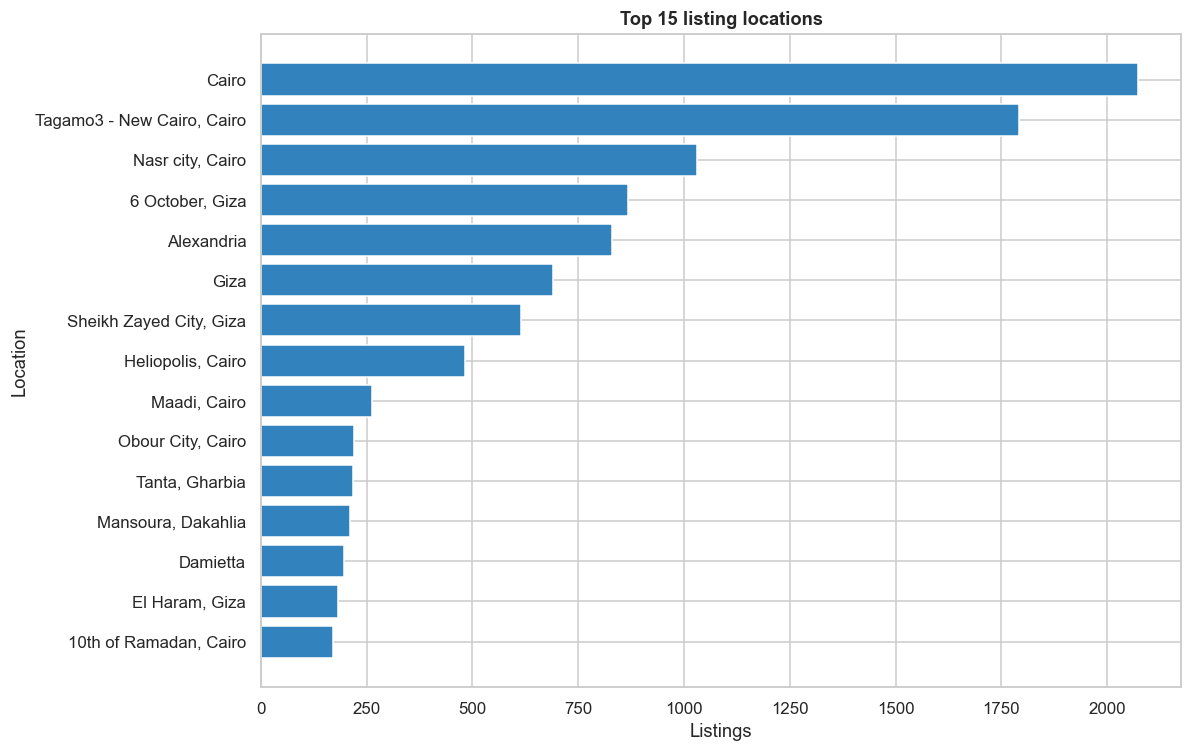

In [6]:
model_counts = (
    df.groupby('model', dropna=False)
    .size()
    .rename('listing_count')
    .sort_values(ascending=False)
)
brand_model_counts = (
    df.groupby(['brand', 'model'], dropna=False)
    .size()
    .rename('listing_count')
    .reset_index()
)

model_uniqueness_summary = pd.DataFrame({
    'Grouping': ['Model name only', 'Brand + model'],
    'Distinct groups': [model_counts.size, len(brand_model_counts)],
    'Groups appearing once': [(model_counts == 1).sum(), (brand_model_counts['listing_count'] == 1).sum()],
    'Groups appearing more than once': [(model_counts > 1).sum(), (brand_model_counts['listing_count'] > 1).sum()],
})
display(model_uniqueness_summary)

print('A model is unique only when its listing count is 1. The detailed brand-model counts below are sorted alphabetically by model, matching the requested check.')
display(brand_model_counts.sort_values(['model', 'brand']).head(20))

city_distribution = (
    df.groupby('city', dropna=False)
    .size()
    .rename('listing_count')
    .reset_index()
    .sort_values('listing_count', ascending=True)
)
print(f'Unique location values: {len(city_distribution):,}')
display(city_distribution)

top_cities = city_distribution.tail(15)
plt.figure(figsize=(11, 7))
plt.barh(top_cities['city'], top_cities['listing_count'], color='#3182bd')
plt.title('Top 15 listing locations')
plt.xlabel('Listings')
plt.ylabel('Location')
plt.tight_layout()
plt.show()

### Temporary EDA helper columns

`km_numeric`, `transmission_label`, and `fuel_display` make the raw fields readable for summaries and plots. 

In [7]:
df_eda = df.copy()
df_eda['km_numeric'] = pd.to_numeric(
    df_eda['km'].astype(str).str.replace(r'[^0-9]', '', regex=True),
    errors='coerce',
)
df_eda['transmission_label'] = df_eda['transmission'].map({1: 'Automatic', 0: 'Manual'}).fillna('Unknown')
fuel_map = {
    'gas': 'Gas',
    'diesel': 'Diesel',
    'natural gas': 'Natural Gas',
    'electric': 'Electric',
    'hybrid': 'Hybrid',
}
df_eda['fuel_display'] = (
    df_eda['fuel'].astype(str).str.strip().str.lower().map(fuel_map).fillna('Unknown')
)

display(df_eda[['km', 'km_numeric', 'transmission', 'transmission_label', 'fuel', 'fuel_display']].head())

,km,km_numeric,transmission,transmission_label,fuel,fuel_display
0,"2,000 KM",2000.0,1,Automatic,Gas,Gas
1,"30,000 KM",30000.0,1,Automatic,Gas,Gas
2,"23,000 KM",23000.0,1,Automatic,Electric,Electric
3,"20,000 KM",20000.0,1,Automatic,Gas,Gas
4,"13,000 KM",13000.0,1,Automatic,Gas,Gas


### Data-quality observations for later preprocessing

These are diagnostic flags, not exclusion rules. The thresholds below are deliberately transparent and are used only to count and inspect records that need a later preprocessing decision.

In [8]:
quality_checks = pd.DataFrame({
    'Issue': [
        'All-missing source columns',
        'Zero-price listings',
        'Zero-kilometre listings',
        'Price at or above 100 million EGP',
        'Mileage at or above 1 million KM',
        'Model year after 2026',
    ],
    'Count': [
        int((df.isna().mean() == 1).sum()),
        int((df_eda['price'] == 0).sum()),
        int((df_eda['km_numeric'] == 0).sum()),
        int((df_eda['price'] >= 100_000_000).sum()),
        int((df_eda['km_numeric'] >= 1_000_000).sum()),
        int((df_eda['year'] > 2026).sum()),
    ],
})
quality_checks['Share of listings (%)'] = (100 * quality_checks['Count'] / len(df_eda)).round(2)
display(quality_checks)

flagged_records = df_eda.loc[
    (df_eda['price'] == 0)
    | (df_eda['km_numeric'] == 0)
    | (df_eda['price'] >= 100_000_000)
    | (df_eda['km_numeric'] >= 1_000_000)
    | (df_eda['year'] > 2026),
    ['id', 'title', 'year', 'price', 'km', 'fuel_display', 'brand', 'model', 'city'],
].sort_values(['price', 'km'], ascending=[False, False])

print(f'Representative flagged records (showing {min(15, len(flagged_records)):,} of {len(flagged_records):,}):')
display(flagged_records.head(15))

,Issue,Count,Share of listings (%)
0,All-missing source columns,3,0.02
1,Zero-price listings,0,0.00
2,Zero-kilometre listings,770,5.29
3,Price at or above 100 million EGP,0,0.00
4,Mileage at or above 1 million KM,40,0.27
5,Model year after 2026,28,0.19


Representative flagged records (showing 15 of 838):


,id,title,year,price,km,fuel_display,brand,model,city
8715,7275020,Nissan Patrol 2016,2016.0,3700000,0 KM,Gas,Nissan,Patrol,Cairo
5861,7286404,Toyota Corolla 1999,1999.0,2750000,0 KM,Gas,Toyota,Corolla,"10th of Ramadan, Cairo"
11699,7264307,Geely Emgrand 2014,2014.0,2600000,0 KM,Natural Gas,Geely,Emgrand,Cairo
917,7301725,Peugeot 408 2027,2027.0,2500000,"8,000 KM",Gas,Peugeot,408,Ismailia
7081,7287315,Volkswagen Tiguan 2026,2026.0,2400000,0 KM,Gas,Volkswagen,Tiguan,Giza
14005,7248021,Mini Cooper 2026,2026.0,2330000,0 KM,Gas,Mini,Cooper,Cairo
4567,7271211,Mercedes E 180 2017,2017.0,2275000,"1,000,000 KM",Gas,Mercedes,E 180,"Sheikh Zayed City, Giza"
7900,7280439,Skoda Kodiaq 2025,2025.0,2270000,0 KM,Gas,Skoda,Kodiaq,Cairo
10513,7270139,Volkswagen Pointer 2006,2006.0,2222222,0 KM,Gas,Volkswagen,Pointer,Sharqia
2971,7298222,Jetour T2 2027,2027.0,2200000,"10,000 KM",Hybrid,Jetour,T2,"Tagamo3 - New Cairo, Cairo"


### Numerical distributions

Price and mileage include extreme values. To keep the axes readable, the price panels and mileage-spread panel show the central 90% (5th to 95th percentile); the mileage distribution and mileage-by-year panels show the central 98%. All axes use comma-separated numeric labels, and the descriptive table retains every raw row.

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,median
price,14556.0,1147299.77,1526414.06,1000.0,78000.0,160000.0,400000.0,700000.0,1250000.0,3700000.0,7500000.0,24000000.0,700000.0
year,14555.0,2014.76,9.16,1950.0,1983.0,1997.0,2010.0,2017.0,2022.0,2025.0,2026.0,2027.0,2017.0
km_numeric,14555.0,216220.04,5190054.48,0.0,0.0,0.0,47000.0,124000.0,200000.0,320000.0,500000.0,555555555.0,124000.0


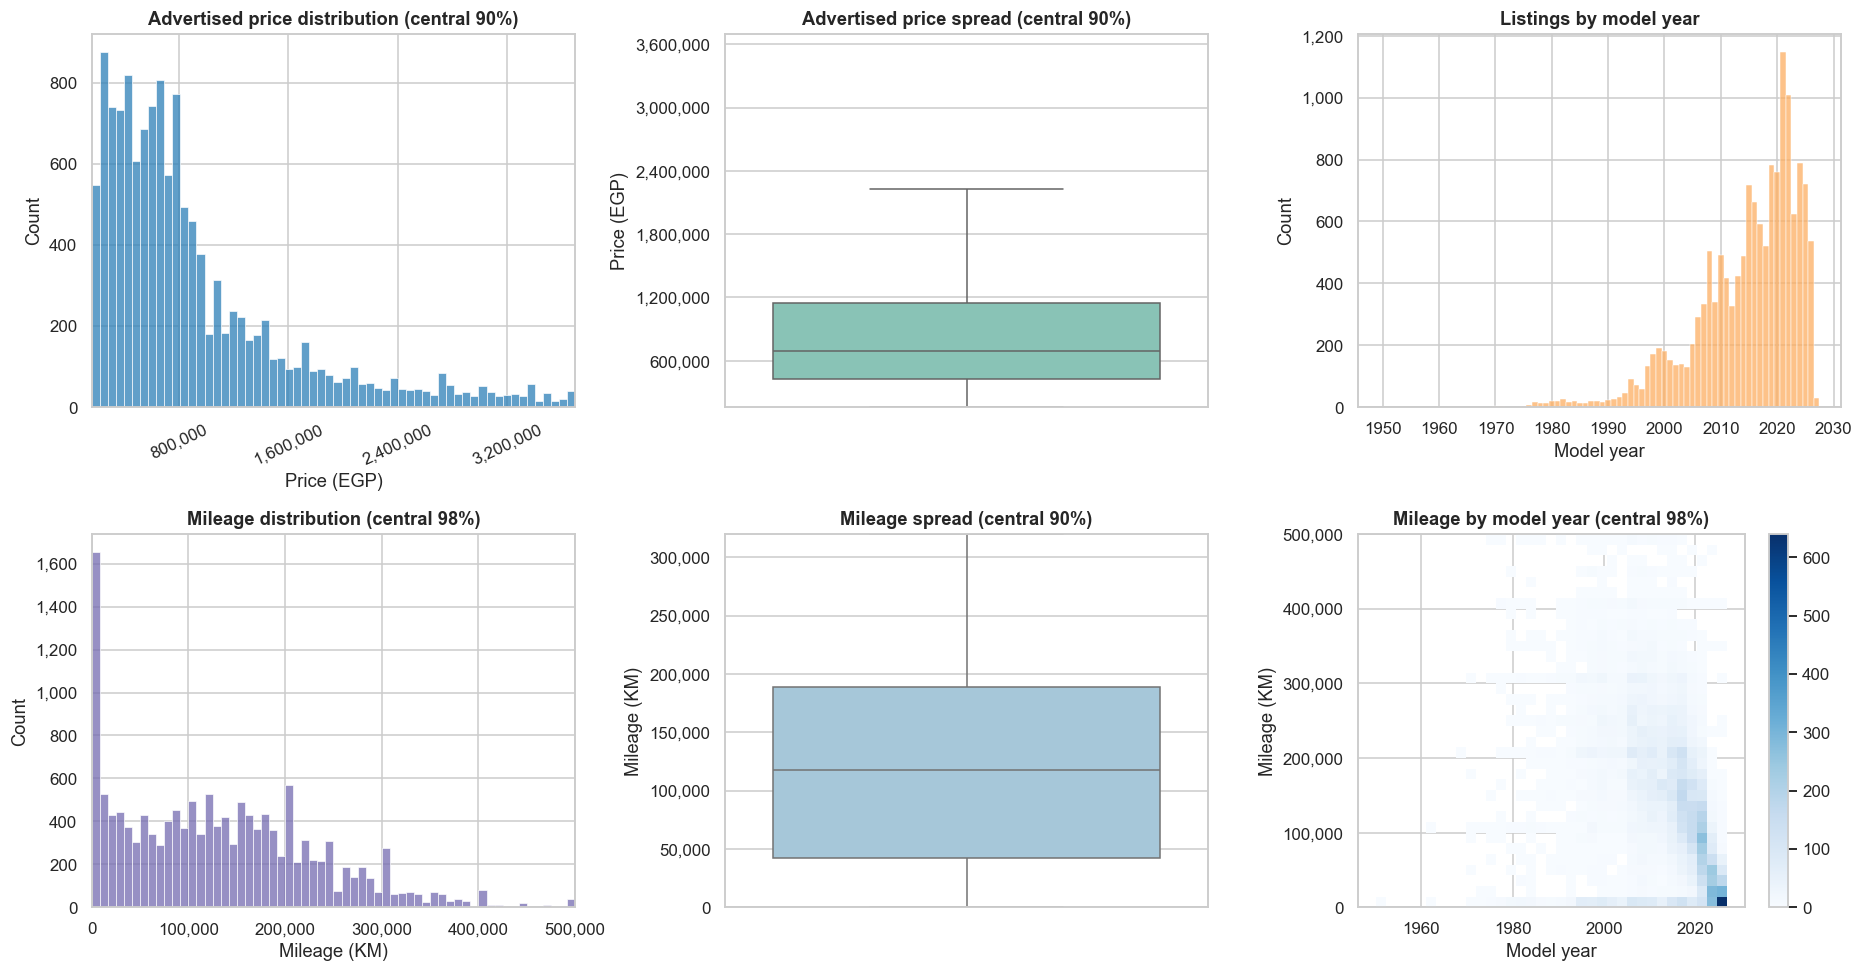

In [9]:
numeric_summary = df_eda[['price', 'year', 'km_numeric']].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).T
numeric_summary['median'] = df_eda[['price', 'year', 'km_numeric']].median()
display(numeric_summary.round(2))

km_limits = df_eda['km_numeric'].quantile([0.01, 0.99])
price_zoom_limits = df_eda['price'].quantile([0.05, 0.95])
mileage_spread_limits = df_eda['km_numeric'].quantile([0.05, 0.95])
price_zoom = df_eda[df_eda['price'].between(*price_zoom_limits)]
km_visible = df_eda[df_eda['km_numeric'].between(*km_limits)]
mileage_spread_zoom = df_eda[df_eda['km_numeric'].between(*mileage_spread_limits)]
numeric_formatter = FuncFormatter(lambda value, _: f'{value:,.0f}')
year_formatter = FuncFormatter(lambda value, _: f'{value:.0f}')

fig, axes = plt.subplots(2, 3, figsize=(17, 9))

sns.histplot(data=price_zoom, x='price', bins=60, ax=axes[0, 0], color='#2c7fb8')
axes[0, 0].set_xlim(price_zoom_limits.iloc[0], price_zoom_limits.iloc[1])
axes[0, 0].set_title('Advertised price distribution (central 90%)')
axes[0, 0].set_xlabel('Price (EGP)')

sns.boxplot(y=price_zoom['price'], ax=axes[0, 1], color='#7fcdbb', showfliers=False)
axes[0, 1].set_ylim(price_zoom_limits.iloc[0], price_zoom_limits.iloc[1])
axes[0, 1].set_title('Advertised price spread (central 90%)')
axes[0, 1].set_ylabel('Price (EGP)')

sns.histplot(data=df_eda, x='year', discrete=True, ax=axes[0, 2], color='#fdae61')
axes[0, 2].set_title('Listings by model year')
axes[0, 2].set_xlabel('Model year')

sns.histplot(data=km_visible, x='km_numeric', bins=60, ax=axes[1, 0], color='#756bb1')
axes[1, 0].set_xlim(km_limits.iloc[0], km_limits.iloc[1])
axes[1, 0].set_title('Mileage distribution (central 98%)')
axes[1, 0].set_xlabel('Mileage (KM)')

sns.boxplot(y=mileage_spread_zoom['km_numeric'], ax=axes[1, 1], color='#9ecae1', showfliers=False)
axes[1, 1].set_ylim(mileage_spread_limits.iloc[0], mileage_spread_limits.iloc[1])
axes[1, 1].set_title('Mileage spread (central 90%)')
axes[1, 1].set_ylabel('Mileage (KM)')

sns.histplot(data=km_visible, x='year', y='km_numeric', bins=35, cbar=True, ax=axes[1, 2], cmap='Blues')
axes[1, 2].set_ylim(km_limits.iloc[0], km_limits.iloc[1])
axes[1, 2].set_title('Mileage by model year (central 98%)')
axes[1, 2].set_xlabel('Model year')
axes[1, 2].set_ylabel('Mileage (KM)')

axes[0, 0].xaxis.set_major_locator(MaxNLocator(nbins=5, prune='both'))
axes[0, 1].yaxis.set_major_locator(MaxNLocator(nbins=6))
axes[0, 1].set_xticks([])
axes[1, 1].set_xticks([])
axes[0, 0].tick_params(axis='x', labelrotation=25)

for ax in axes.flat:
    ax.xaxis.set_major_formatter(numeric_formatter)
    ax.yaxis.set_major_formatter(numeric_formatter)

axes[0, 2].xaxis.set_major_formatter(year_formatter)
axes[1, 2].xaxis.set_major_formatter(year_formatter)

plt.tight_layout()
save_figure(fig, 'numerical_distributions.png')
plt.show()

### Market composition

Brand, model, and location have many categories. The following charts show only the most frequent categories and label the limit explicitly, less frequent categories remain present in the underlying data.

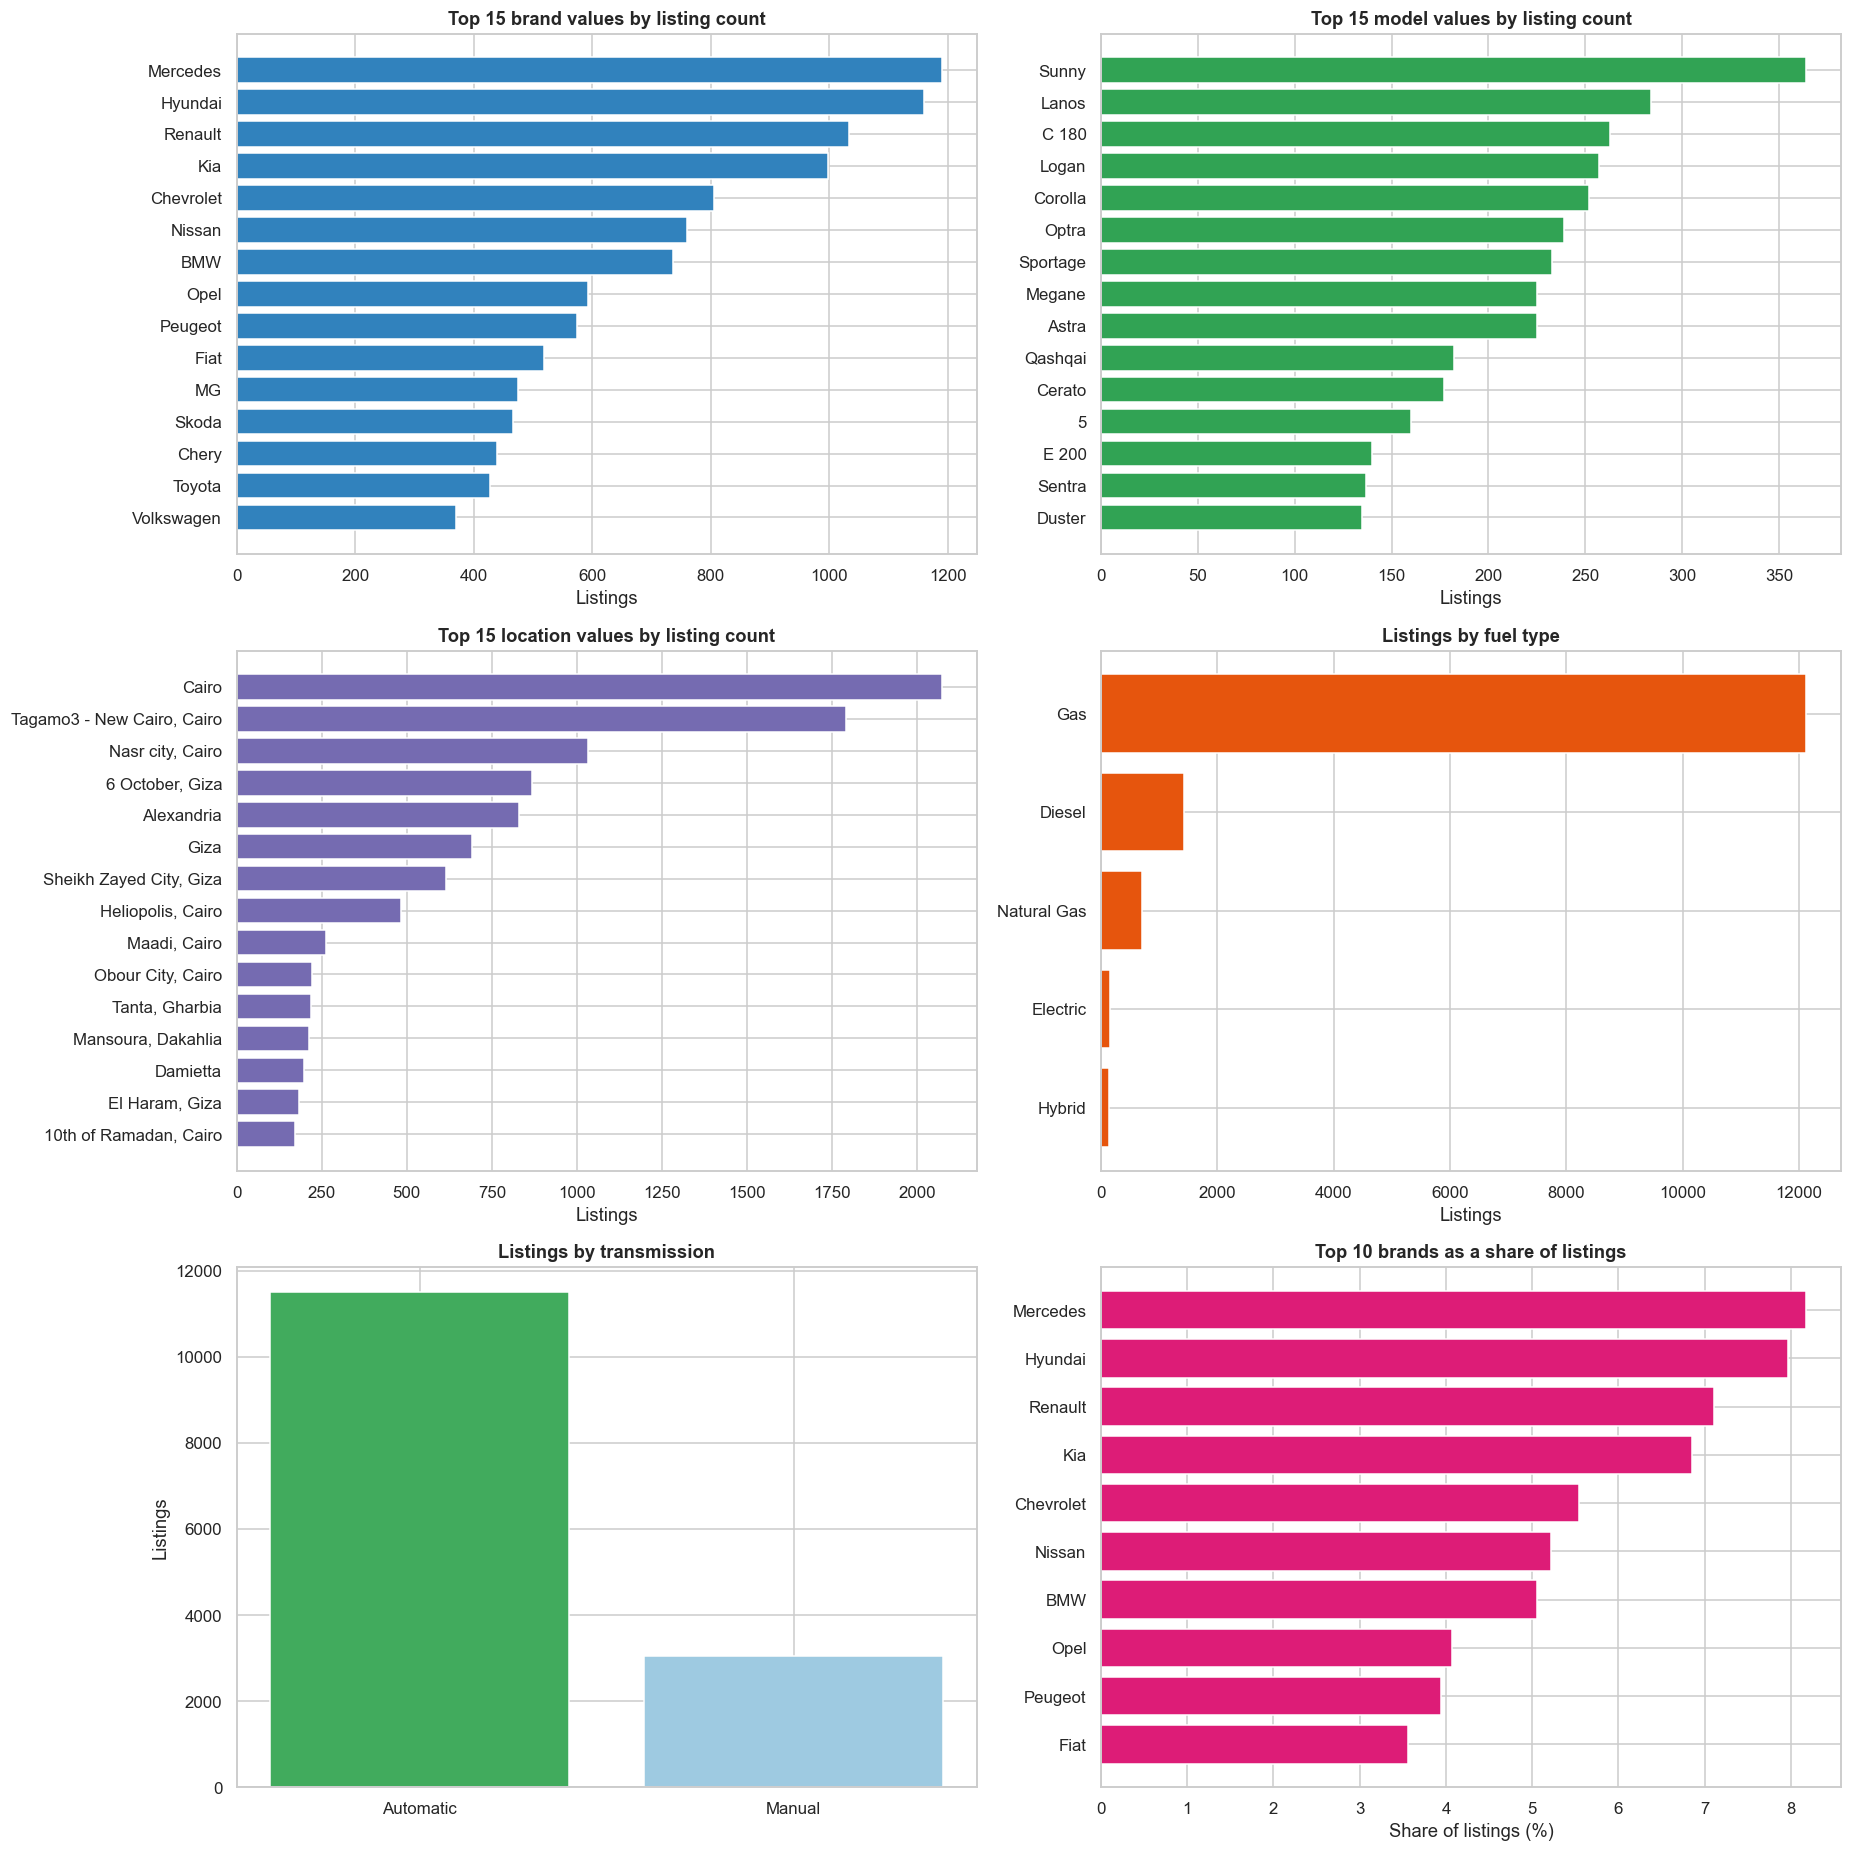

In [10]:
def top_counts(frame: pd.DataFrame, column: str, n: int = 15) -> pd.DataFrame:
    return frame[column].value_counts().head(n).sort_values()

fig, axes = plt.subplots(3, 2, figsize=(17, 17))

for ax, column, label, color in [
    (axes[0, 0], 'brand', 'Brand', '#3182bd'),
    (axes[0, 1], 'model', 'Model', '#31a354'),
    (axes[1, 0], 'city', 'Location', '#756bb1'),
]:
    counts = top_counts(df_eda, column)
    ax.barh(counts.index, counts.values, color=color)
    ax.set_title(f'Top 15 {label.lower()} values by listing count')
    ax.set_xlabel('Listings')

fuel_counts = df_eda['fuel_display'].value_counts().sort_values()
axes[1, 1].barh(fuel_counts.index, fuel_counts.values, color='#e6550d')
axes[1, 1].set_title('Listings by fuel type')
axes[1, 1].set_xlabel('Listings')

transmission_counts = df_eda['transmission_label'].value_counts().reindex(['Automatic', 'Manual', 'Unknown']).dropna()
axes[2, 0].bar(transmission_counts.index, transmission_counts.values, color=['#41ab5d', '#9ecae1', '#bdbdbd'])
axes[2, 0].set_title('Listings by transmission')
axes[2, 0].set_ylabel('Listings')

brand_share = df_eda['brand'].value_counts(normalize=True).head(10).mul(100).sort_values()
axes[2, 1].barh(brand_share.index, brand_share.values, color='#dd1c77')
axes[2, 1].set_title('Top 10 brands as a share of listings')
axes[2, 1].set_xlabel('Share of listings (%)')

plt.tight_layout()
plt.show()

### Price relationships and potential predictive signals

The following comparisons are descriptive associations, not causal effects. Logarithmic price axes make the dominant price range readable; the zero-price listing is omitted only from those specific log-price plots.

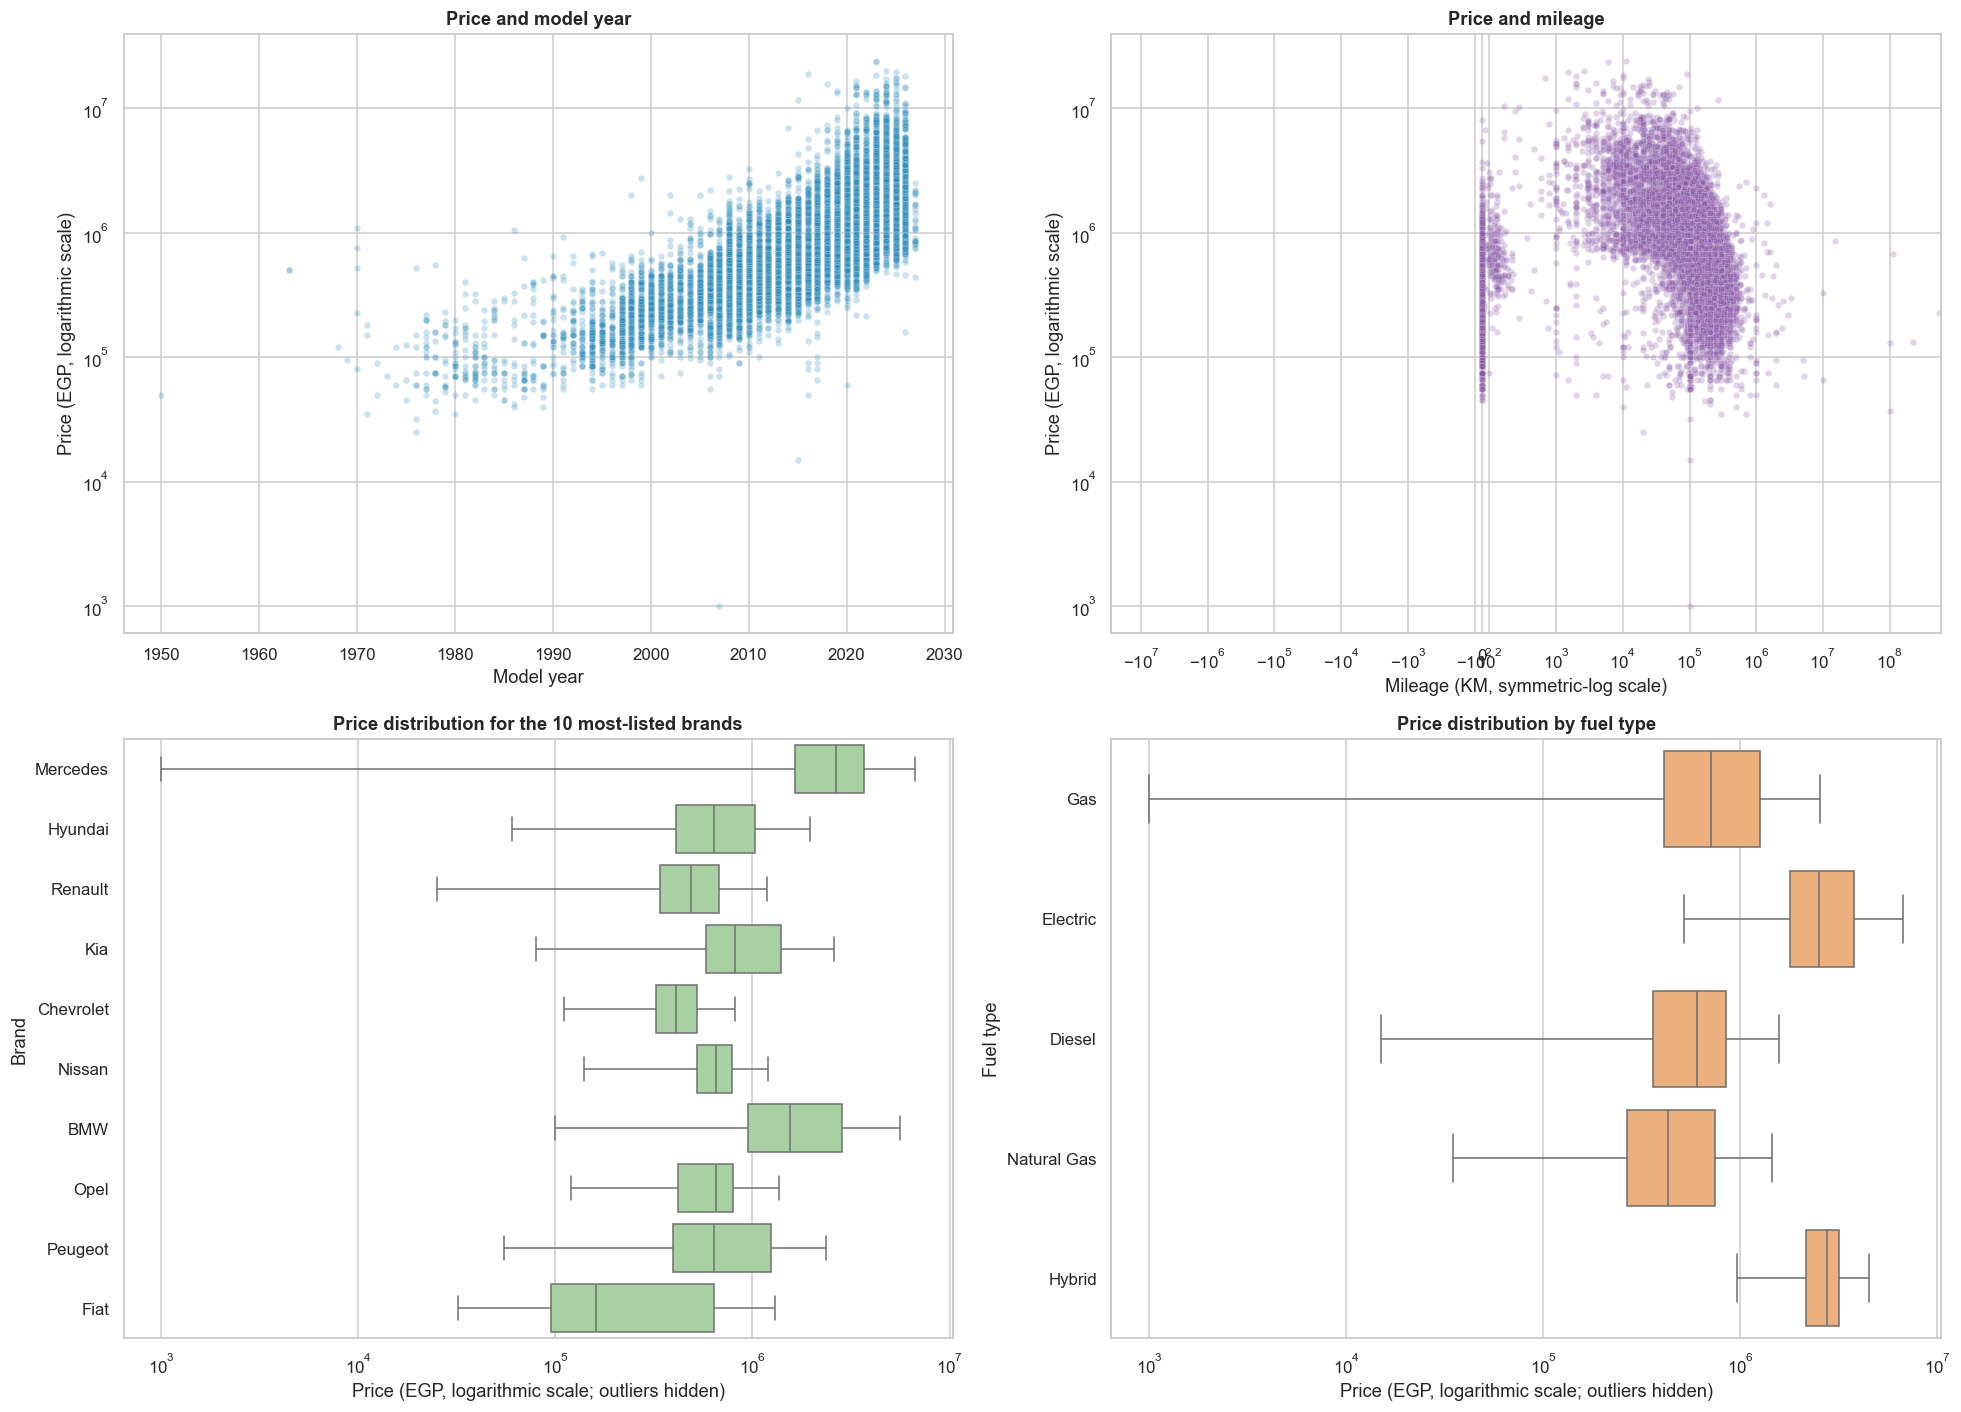

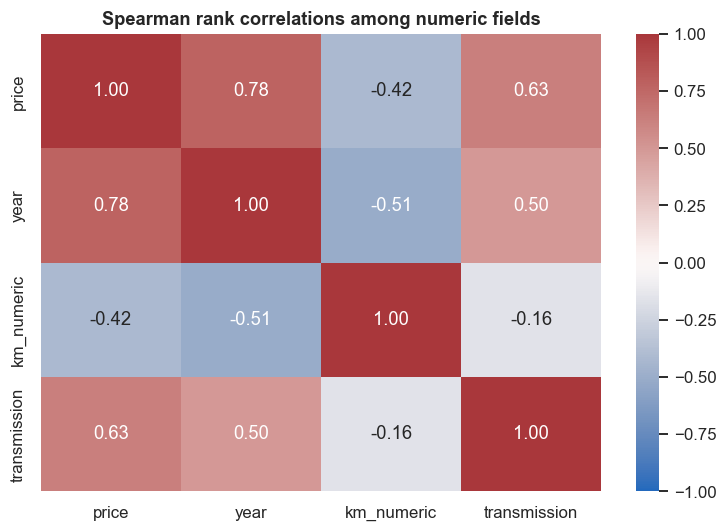

,Median price (EGP)
transmission_label,
Manual,250000.0
Automatic,825000.0


In [11]:
positive_price = df_eda[df_eda['price'] > 0].copy()
top_brands = df_eda['brand'].value_counts().head(10).index
top_brand_prices = positive_price[positive_price['brand'].isin(top_brands)]

fig, axes = plt.subplots(2, 2, figsize=(18, 13))

sns.scatterplot(data=positive_price, x='year', y='price', alpha=0.25, s=18, ax=axes[0, 0], color='#2b8cbe')
axes[0, 0].set_yscale('log')
axes[0, 0].set_title('Price and model year')
axes[0, 0].set_xlabel('Model year')
axes[0, 0].set_ylabel('Price (EGP, logarithmic scale)')

sns.scatterplot(data=positive_price, x='km_numeric', y='price', alpha=0.25, s=18, ax=axes[0, 1], color='#8856a7')
axes[0, 1].set_xscale('symlog', linthresh=1_000)
axes[0, 1].set_yscale('log')
axes[0, 1].set_title('Price and mileage')
axes[0, 1].set_xlabel('Mileage (KM, symmetric-log scale)')
axes[0, 1].set_ylabel('Price (EGP, logarithmic scale)')

sns.boxplot(data=top_brand_prices, x='price', y='brand', order=top_brands, ax=axes[1, 0], color='#a1d99b', showfliers=False)
axes[1, 0].set_xscale('log')
axes[1, 0].set_title('Price distribution for the 10 most-listed brands')
axes[1, 0].set_xlabel('Price (EGP, logarithmic scale; outliers hidden)')
axes[1, 0].set_ylabel('Brand')

sns.boxplot(data=positive_price, x='price', y='fuel_display', ax=axes[1, 1], color='#fdae6b', showfliers=False)
axes[1, 1].set_xscale('log')
axes[1, 1].set_title('Price distribution by fuel type')
axes[1, 1].set_xlabel('Price (EGP, logarithmic scale; outliers hidden)')
axes[1, 1].set_ylabel('Fuel type')

plt.tight_layout()
plt.show()

correlation_columns = ['price', 'year', 'km_numeric', 'transmission']
spearman_corr = df_eda[correlation_columns].corr(method='spearman')
plt.figure(figsize=(7, 5))
sns.heatmap(spearman_corr, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1)
plt.title('Spearman rank correlations among numeric fields')
plt.tight_layout()
plt.show()

median_price_by_transmission = positive_price.groupby('transmission_label')['price'].median().sort_values()
display(median_price_by_transmission.rename('Median price (EGP)').to_frame())

### Findings and next steps

In [12]:
top_brand = df_eda['brand'].value_counts().idxmax()
top_brand_count = int(df_eda['brand'].value_counts().max())
median_price = df_eda['price'].median()
price_p99 = df_eda['price'].quantile(0.99)
year_price_corr = spearman_corr.loc['year', 'price']
km_price_corr = spearman_corr.loc['km_numeric', 'price']
empty_columns = ', '.join(profile.index[profile['missing_%'].eq(100)].tolist())

display(Markdown(f'''### Key observations

- The dataset contains **{len(df_eda):,} raw listings** and **{df_eda['id'].nunique():,} unique listing IDs**. `{top_brand}` is the most common brand, with {top_brand_count:,} listings.
- Advertised price is strongly right-skewed: the median is **{median_price:,.0f} EGP**, while the 99th percentile is **{price_p99:,.0f} EGP**. Means should therefore be interpreted carefully.
- In this sample, price has a positive Spearman association with model year ({year_price_corr:.2f}) and a negative association with recorded mileage ({km_price_corr:.2f}). These are associations, not causal estimates.
- Brand, model, location, fuel type, transmission, year, and mileage are plausible future model inputs. `id` and `fingerprint` should remain identifiers rather than predictive features.

### Deferred to preprocessing

- Resolve the all-missing fields: **{empty_columns}**.
- Decide how to treat zero values, extreme prices and mileages, future model years, and inconsistent categorical labels.
- Convert selected fields, encode categories, scale features when required by the chosen model, and construct train/validation/test splits without leakage.
'''))

### Key observations

- The dataset contains **14,556 raw listings** and **14,556 unique listing IDs**. `Mercedes` is the most common brand, with 1,190 listings.
- Advertised price is strongly right-skewed: the median is **700,000 EGP**, while the 99th percentile is **7,500,000 EGP**. Means should therefore be interpreted carefully.
- In this sample, price has a positive Spearman association with model year (0.78) and a negative association with recorded mileage (-0.42). These are associations, not causal estimates.
- Brand, model, location, fuel type, transmission, year, and mileage are plausible future model inputs. `id` and `fingerprint` should remain identifiers rather than predictive features.

### Deferred to preprocessing

- Resolve the all-missing fields: **ad_date, color, class**.
- Decide how to treat zero values, extreme prices and mileages, future model years, and inconsistent categorical labels.
- Convert selected fields, encode categories, scale features when required by the chosen model, and construct train/validation/test splits without leakage.


## 4. Preprocessing

This section applies the data-quality decisions from the EDA to the **full cleaned snapshot**, derives numeric mileage, and groups listing locations by governorate. Imputation, scaling and categorical encoding are deliberately deferred until *after* the train/test split (Section 7), so that no information from the test set leaks into the fitted transformations.

### Cleaning decisions from EDA

The input is already deduplicated. The EDA identified zero prices, prices of at least 100 million EGP, mileage of at least one million KM, and years beyond 2026 as invalid. This notebook removes those records and rows with a missing mileage. It keeps zero-mileage records, because they may be genuine new-car listings.

The all-missing `ad_date`, `color`, and `class` columns are excluded. `fingerprint` is an identifier and `title` overlaps with brand, model, and year, so neither is included in the model-ready output. `listing_id` is retained only for traceability and must not be used as a model feature.

In [13]:
MAX_PRICE_EGP = 100_000_000
MAX_MILEAGE_KM = 1_000_000
MIN_YEAR = 1950
MAX_YEAR = 2026

working = df.copy()
working['mileage_km'] = pd.to_numeric(
    working['km'].astype('string').str.replace(r'[^0-9]', '', regex=True),
    errors='coerce',
)

invalid_price = working['price'].isna() | working['price'].le(0) | working['price'].ge(MAX_PRICE_EGP)
invalid_mileage = working['mileage_km'].isna() | working['mileage_km'].ge(MAX_MILEAGE_KM)
invalid_year = working['year'].isna() | ~working['year'].between(MIN_YEAR, MAX_YEAR)
valid_rows = ~(invalid_price | invalid_mileage | invalid_year)

cleaning_audit = pd.DataFrame({
    'rule': [
        'Invalid price (missing, zero, or at least 100 million EGP)',
        'Invalid mileage (missing or at least 1 million KM)',
        'Invalid model year (outside 1950–2026)',
        'Removed by one or more rules',
    ],
    'rows': [invalid_price.sum(), invalid_mileage.sum(), invalid_year.sum(), (~valid_rows).sum()],
})
cleaning_audit['share_of_input_%'] = (100 * cleaning_audit['rows'] / len(working)).round(2)
display(cleaning_audit)

cleaned = working.loc[valid_rows].copy()
print(f'Rows retained after numeric validation: {len(cleaned):,} ({len(cleaned) / len(working):.1%} of input).')

,rule,rows,share_of_input_%
0,"Invalid price (missing, zero, or at least 100 ...",0,0.00
1,Invalid mileage (missing or at least 1 million...,41,0.28
2,Invalid model year (outside 1950–2026),29,0.20
3,Removed by one or more rules,69,0.47


Rows retained after numeric validation: 14,487 (99.5% of input).


### Standardize features and derive governorate

The supplied city-to-governorate grouping is used below. Source locations are commonly stored as `district, governorate`; therefore `find_gover` checks every comma-separated component case-insensitively. Locations without a supplied mapping are preserved as `Other / Unmapped` for review rather than discarded.

In [14]:
GOVERNORATE_CITIES = {
    'Cairo': ['Cairo', 'Mohandessin', 'Nasr city', 'El Marg', 'Sheraton', 'Heliopolis', 'El Manial', 'Mokattam', 'El Gamaleya', 'Al Shorouk', 'Shobra', 'Tagamo3 - New Cairo', 'New Administrative Capital', 'Badr City', 'Zamalek', 'Ain Shams', 'Madinaty', 'Maadi', 'Warraq', 'El Katameya', 'El Salam City'],
    'Giza': ['Imbaba', 'Kerdasa', 'Dokki', 'Saft El Laban', 'El Haram', 'Sheikh Zayed City', '6 October', 'Giza', 'Pyramids Gardens'],
    'Dakahlia': ['Mit Ghamr', 'El Senbellawein', 'Dikirnis', 'Mansoura', 'Dakahlia'],
    'Red Sea': ['Ras Gharib', 'Safaga', 'Hurghada', 'El Gouna', 'Red Sea'],
    'Luxor': ['Luxor'], 'Sharkia': ['Dyarb Negm', 'Bilbeis'], 'Damietta': ['Damietta'],
    'Monufia': ['Sadat City', 'Shibin el Kom', 'El Bagour', 'Ashmoun', 'Menouf', 'Quesna', 'Monufia', 'Tala'],
    'Alexandria': ['Alexandria', 'Borg el arab', 'Amreya', 'Abu Qir', 'Agamy'],
    'Qalubia': ['Kafr Shukr', 'Banha', 'Khanka', 'Touhk', 'El Qanater El Khayreya', 'Qalyub', 'Shibin El Qanater', 'Obour City', 'Qalyubia'],
    'Kafr el-Sheikh': ['Kafr el-Sheikh'], 'El Minya': ['El Minya'],
    'ALGharbia': ['El Mahalla', 'Kafr El Zayat', 'Zefta', 'Tanta', 'Gharbia'],
    'ALSharqia': ['Faqous', 'Minya Al Qamh', 'Zagazig', 'Sharqia', 'Abu Kabir', '10th of Ramadan'],
    'Helwan': ['Helwan'], 'Aswan': ['Kom Ombo', 'Aswan'], 'Matrouh': ['Marsa Matrouh', 'El-Alamein'],
    'South Sinai': ['Sharm el-Sheikh'], 'North Sinai': ['El-Arish'], 'Sohag': ['Sohag'],
    'Ismailia': ['Ismailia'], 'Suez': ['Suez'], 'Qena': ['Qena'],
    'ElBeheira': ['Damanhur', 'Kom Hamada', 'Edku', 'Kafr el-Dawwar', 'Abu Hummus', 'Rosetta', 'Beheira'],
    'Beni Suef': ['Beni Suef'], 'El Wadi El Gedid': ['El Wadi El Gedid'],
    'Faiyum': ['Faiyum'], 'Asyut': ['Asyut'], 'Port Said': ['Port Said'],
}

CITY_TO_GOVERNORATE = {
    city.casefold(): governorate
    for governorate, cities in GOVERNORATE_CITIES.items()
    for city in cities
}

def find_gover(city: object) -> str:
    """Return a governorate for a city/district, or an empty string if unmapped."""
    if pd.isna(city):
        return ''
    for city_part in str(city).split(','):
        governorate = CITY_TO_GOVERNORATE.get(city_part.strip().casefold())
        if governorate:
            return governorate
    return ''

def normalize_text(series: pd.Series) -> pd.Series:
    return series.astype('string').str.strip().replace('', pd.NA)

fuel_map = {
    'gas': 'Gas', 'diesel': 'Diesel', 'natural gas': 'Natural Gas',
    'electric': 'Electric', 'hybrid': 'Hybrid',
}

cleaned['brand'] = normalize_text(cleaned['brand'])
cleaned['model'] = normalize_text(cleaned['model'])
location = normalize_text(cleaned['city'])
cleaned['governorate'] = location.map(find_gover).replace('', 'Other / Unmapped')
cleaned['fuel'] = normalize_text(cleaned['fuel']).str.lower().map(fuel_map).fillna('Unknown')
cleaned['transmission'] = cleaned['transmission'].map({1: 'Automatic', 0: 'Manual'}).fillna('Unknown')

governorate_distribution = (
    cleaned.groupby('governorate', dropna=False).size().rename('listing_count')
    .sort_values(ascending=False).to_frame()
)
display(governorate_distribution)

unmapped_locations = (
    location.loc[cleaned['governorate'].eq('Other / Unmapped')]
    .value_counts().rename('listing_count').to_frame()
)
print(f'Unmapped listings: {unmapped_locations["listing_count"].sum() if not unmapped_locations.empty else 0:,}')
display(unmapped_locations.head(20))

,listing_count
governorate,
Cairo,7063
Giza,2744
Alexandria,1127
Qalubia,486
ALGharbia,410
ALSharqia,404
Dakahlia,316
Monufia,248
Damietta,195


Unmapped listings: 171


,listing_count
city,
El Faiyum,84
Ben Suef,28
"Al Abbassia, Greater Cairo ( Cairo + Giza)",22
Mariotya,7
South Sinai,4
Honda City 2005,4
Honda City 2007,3
"Bulaq, Greater Cairo ( Cairo + Giza)",3
Honda City 2016,3


### Select modelling columns

The modelling table keeps the target (`price`), the numeric vehicle information, the standardised categorical fields, and governorate as the only location field. `listing_id` is kept only for traceability and is never given to a model.

In [15]:
MODEL_READY_COLUMNS = [
    'id', 'price', 'year', 'mileage_km', 'transmission', 'fuel',
    'brand', 'model', 'governorate',
]

cars = (
    cleaned.loc[:, MODEL_READY_COLUMNS]
    .rename(columns={'id': 'listing_id'})
    .sort_values('listing_id')
    .reset_index(drop=True)
)

# Sanity checks on the modelling table.
assert cars['listing_id'].is_unique
assert cars['price'].gt(0).all() and cars['price'].lt(MAX_PRICE_EGP).all()
assert cars['mileage_km'].between(0, MAX_MILEAGE_KM, inclusive='left').all()
assert cars['year'].between(MIN_YEAR, MAX_YEAR).all()
assert cars.notna().all().all()

print(f'Modelling table: {len(cars):,} rows × {cars.shape[1]} columns')
display(cars.head())
display(cars.isna().sum().rename('missing_values').to_frame())

Modelling table: 14,487 rows × 9 columns


,listing_id,price,year,mileage_km,transmission,fuel,brand,model,governorate
0,5145507,730000,2021.0,70000,Automatic,Gas,MG,5,Cairo
1,6853043,280000,2011.0,180000,Automatic,Gas,Speranza,A620,Kafr el-Sheikh
2,6885487,1120000,2018.0,155000,Automatic,Gas,Opel,Grandland,Cairo
3,6891660,335000,2005.0,250000,Manual,Gas,Opel,Corsa,Alexandria
4,6893295,310000,2003.0,200000,Automatic,Gas,Peugeot,406,Cairo


,missing_values
listing_id,0
price,0
year,0
mileage_km,0
transmission,0
fuel,0
brand,0
model,0
governorate,0


## 5. Train/test split

`price` is the target and `listing_id` is retained only for traceability. 20% of listings are held out as a test set. That test set is used **once**, in Section 11; all model selection and tuning use cross-validation on the training set only. The split is stratified by price decile, so both sets cover the same price range.

In [16]:
TARGET_COLUMN = 'price'
ID_COLUMN = 'listing_id'
NUMERIC_FEATURES = ['year', 'mileage_km']
CATEGORICAL_FEATURES = ['transmission', 'fuel', 'brand', 'model', 'governorate']
CLUSTER_FEATURES = ['year', 'mileage_km']  # inputs to the unsupervised K-Means step
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X = cars.loc[:, FEATURE_COLUMNS].copy()
y = cars[TARGET_COLUMN].copy()
listing_ids = cars[ID_COLUMN].copy()

price_bins = pd.qcut(y, q=10, duplicates='drop')

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, listing_ids,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=price_bins,
)

split_summary = pd.DataFrame({
    'rows': [len(X_train), len(X_test)],
    'median_price': [y_train.median(), y_test.median()],
    'mean_price': [y_train.mean(), y_test.mean()],
}, index=['train', 'test']).round(0)
display(split_summary)
print(f'Predictor columns: {FEATURE_COLUMNS}')

,rows,median_price,mean_price
train,11589,695000.0,1149025.0
test,2898,700000.0,1148284.0


Predictor columns: ['year', 'mileage_km', 'transmission', 'fuel', 'brand', 'model', 'governorate']


## 6. Unsupervised feature engineering: K-Means clusters

K-Means is applied to the **standardised model year and mileage** of the training listings. The aim is to discover vehicle age/usage segments (for example "new, low-mileage" vs "old, high-mileage"). Each listing's cluster membership is then one-hot encoded and added as extra features for the supervised models.

The number of clusters *k* is chosen on the training set only, using the elbow in within-cluster inertia and the silhouette score. The *k* with the highest silhouette is selected.

In [17]:
K_RANGE = range(2, 11)
scaled_cluster_inputs = StandardScaler().fit_transform(X_train[CLUSTER_FEATURES])

k_rows = []
for k in K_RANGE:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(scaled_cluster_inputs)
    k_rows.append({
        'k': k,
        'inertia': kmeans.inertia_,
        'silhouette': silhouette_score(
            scaled_cluster_inputs, kmeans.labels_, sample_size=5_000, random_state=RANDOM_STATE
        ),
    })
k_selection = pd.DataFrame(k_rows)
N_CLUSTERS = int(k_selection.loc[k_selection['silhouette'].idxmax(), 'k'])

display(k_selection.round(3))
print(f'Selected number of clusters (highest silhouette): k = {N_CLUSTERS}')

,k,inertia,silhouette
0,2,12593.156,0.453
1,3,9153.030,0.462
2,4,6739.725,0.429
3,5,5736.110,0.385
4,6,4809.239,0.393
5,7,4100.034,0.410
6,8,3539.369,0.408
7,9,3124.674,0.400
8,10,2819.464,0.408


Selected number of clusters (highest silhouette): k = 3


The transformer below wraps the scaler and K-Means so that it can sit **inside** the scikit-learn pipeline. The clusters are therefore re-fitted on the training portion of every cross-validation fold, which avoids leakage. It outputs one binary column per cluster.

,listings,median_year,median_mileage_km,median_price_egp
cluster,,,,
1,1288,1999.0,98000.0,210000.0
2,3888,2011.0,227750.0,460000.0
0,6413,2021.0,73000.0,1030000.0


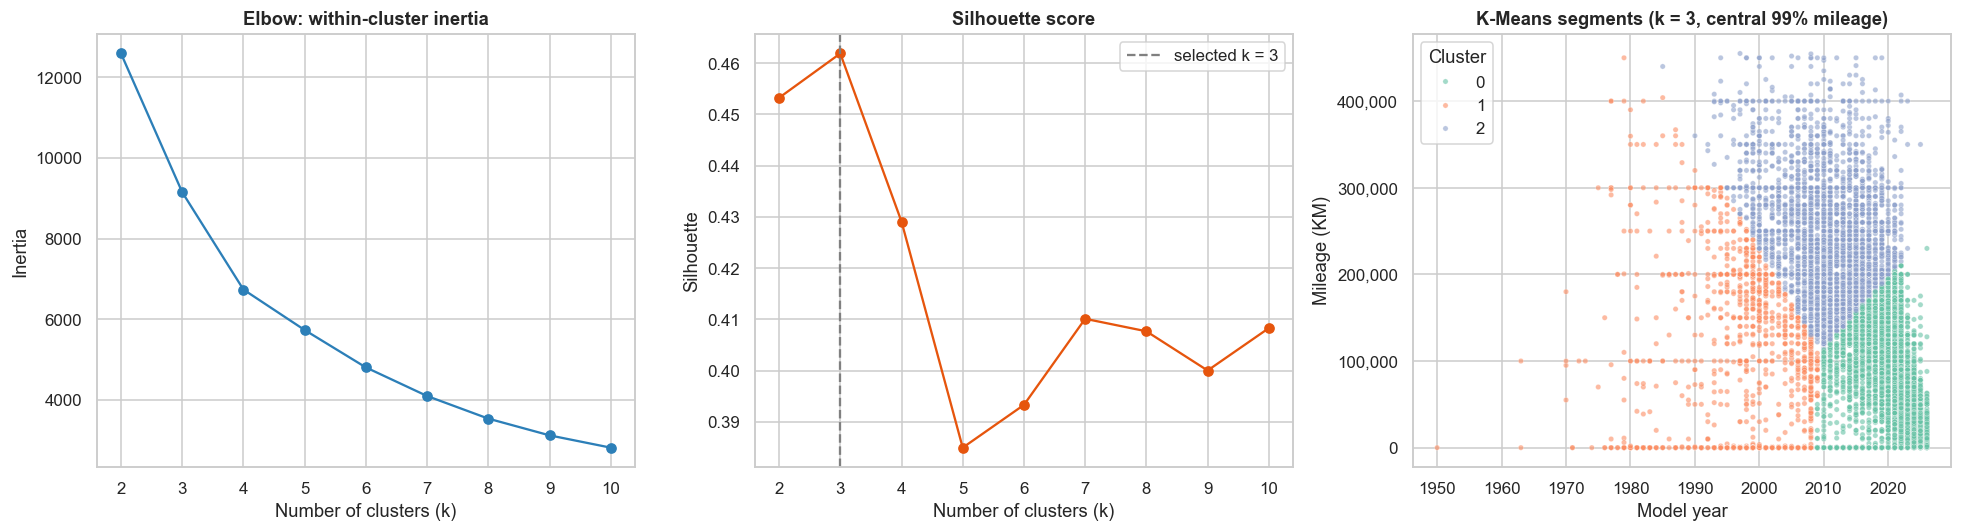

In [18]:
class KMeansClusterFeatures(BaseEstimator, TransformerMixin):
    """Standardise the input columns, fit K-Means, and output one-hot cluster membership."""

    def __init__(self, n_clusters=3, random_state=RANDOM_STATE):
        self.n_clusters = n_clusters
        self.random_state = random_state

    def fit(self, X, y=None):
        self.scaler_ = StandardScaler().fit(X)
        self.kmeans_ = KMeans(
            n_clusters=self.n_clusters, n_init=10, random_state=self.random_state
        ).fit(self.scaler_.transform(X))
        return self

    def predict(self, X):
        return self.kmeans_.predict(self.scaler_.transform(X))

    def transform(self, X):
        return np.eye(self.n_clusters)[self.predict(X)]

    def get_feature_names_out(self, input_features=None):
        return np.array([f'cluster_{i}' for i in range(self.n_clusters)], dtype=object)


# Profile the clusters found on the full training set.
cluster_model = KMeansClusterFeatures(n_clusters=N_CLUSTERS).fit(X_train[CLUSTER_FEATURES])
train_clusters = cluster_model.predict(X_train[CLUSTER_FEATURES])

cluster_profile = (
    X_train.assign(cluster=train_clusters, price=y_train)
    .groupby('cluster')
    .agg(listings=('price', 'size'), median_year=('year', 'median'),
         median_mileage_km=('mileage_km', 'median'), median_price_egp=('price', 'median'))
    .sort_values('median_year')
)
display(cluster_profile)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(k_selection['k'], k_selection['inertia'], marker='o', color='#2c7fb8')
axes[0].set_title('Elbow: within-cluster inertia')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Inertia')
axes[1].plot(k_selection['k'], k_selection['silhouette'], marker='o', color='#e6550d')
axes[1].axvline(N_CLUSTERS, color='grey', linestyle='--', label=f'selected k = {N_CLUSTERS}')
axes[1].set_title('Silhouette score')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette')
axes[1].legend()
visible = X_train['mileage_km'].le(X_train['mileage_km'].quantile(0.99))
sns.scatterplot(
    x=X_train.loc[visible, 'year'], y=X_train.loc[visible, 'mileage_km'],
    hue=train_clusters[visible.to_numpy()], palette='Set2', s=12, alpha=0.6, ax=axes[2],
)
axes[2].set_title(f'K-Means segments (k = {N_CLUSTERS}, central 99% mileage)')
axes[2].set_xlabel('Model year')
axes[2].set_ylabel('Mileage (KM)')
axes[2].yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
axes[2].legend(title='Cluster')
plt.tight_layout()
save_figure(fig, 'kmeans_selection.png')
plt.show()

## 7. Modelling pipeline and cross-validation setup

Every model is wrapped in a single scikit-learn pipeline, so that **all** preprocessing is fitted inside each cross-validation fold:

- **Numeric** (`year`, `mileage_km`): median imputation, then standardisation.
- **Categorical** (`transmission`, `fuel`, `brand`, `model`, `governorate`): most-frequent imputation, then one-hot encoding. `handle_unknown='ignore'` makes the pipeline safe for brands or models that appear only in a validation or test fold.
- **K-Means clusters** (optional): one-hot cluster membership from Section 6.
- **Target**: the pipeline is wrapped in a `TransformedTargetRegressor`. With `log_target=True`, the model is trained on `log(price)` and its predictions are converted back to EGP with `exp`. All metrics are therefore always computed in EGP, so raw-target and log-target models are directly comparable.

Cross-validation uses 5 shuffled folds. **MAE** (mean absolute error in EGP) is the primary metric for model selection and tuning. RMSE, R² and MAPE are reported alongside it.

In [19]:
def build_preprocessor(use_clusters: bool = True) -> ColumnTransformer:
    transformers = [
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler()),
        ]), NUMERIC_FEATURES),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('one_hot', OneHotEncoder(handle_unknown='ignore')),
        ]), CATEGORICAL_FEATURES),
    ]
    if use_clusters:
        transformers.append(('kmeans', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('clusters', KMeansClusterFeatures(n_clusters=N_CLUSTERS)),
        ]), CLUSTER_FEATURES))
    return ColumnTransformer(transformers, remainder='drop')


def build_model(regressor, log_target: bool, use_clusters: bool = True) -> TransformedTargetRegressor:
    """Preprocessing + regressor, optionally trained on log(price). Predictions are always in EGP."""
    pipeline = Pipeline([('preprocess', build_preprocessor(use_clusters)), ('model', regressor)])
    if log_target:
        return TransformedTargetRegressor(regressor=pipeline, func=np.log, inverse_func=np.exp)
    return TransformedTargetRegressor(regressor=pipeline)  # identity transform = raw price


CV = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
SCORING = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2',
    'MAPE': 'neg_mean_absolute_percentage_error',
}
PRIMARY_METRIC = 'MAE'


def summarise_cv(cv_results: dict) -> dict:
    """Convert cross_validate output into positive mean/std values for each metric."""
    summary = {}
    for metric in SCORING:
        scores = cv_results[f'test_{metric}']
        scores = scores if metric == 'R2' else -scores
        if metric == 'MAPE':
            scores = scores * 100
        summary[metric] = scores.mean()
        summary[f'{metric}_std'] = scores.std()
    return summary


def regression_metrics(y_true, y_pred) -> dict:
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': root_mean_squared_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
        'MAPE': 100 * mean_absolute_percentage_error(y_true, y_pred),
    }


feature_count = build_preprocessor().fit(X_train).transform(X_train.head()).shape[1]
print(f'Encoded feature count (with {N_CLUSTERS} cluster columns): {feature_count:,}')

Encoded feature count (with 3 cluster columns): 1,013


## 8. Baseline comparison: raw vs log-transformed price

Each supervised model is first cross-validated with default hyperparameters, once on raw price and once on log price. The target with the lower CV MAE is kept for that model and used during tuning.

- **Multiple linear regression**: ordinary least squares, with no hyperparameters.
- **Ridge regression**: linear regression with an L2 penalty `alpha`, tuned in Section 9.
- **Decision tree regressor**: a single CART tree.
- **Random forest regressor**: a bagged ensemble of decision trees.

In [20]:
BASELINE_MODELS = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeRegressor(random_state=RANDOM_STATE),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
}

baseline_rows = []
for model_name, regressor in BASELINE_MODELS.items():
    for target_name, log_target in [('Raw price', False), ('Log price', True)]:
        start = time.perf_counter()
        results = cross_validate(
            build_model(clone(regressor), log_target), X_train, y_train,
            cv=CV, scoring=SCORING,
        )
        baseline_rows.append({
            'Model': model_name, 'Target': target_name, 'log_target': log_target,
            **summarise_cv(results), 'seconds': time.perf_counter() - start,
        })

baseline_results = pd.DataFrame(baseline_rows)
best_target_rows = baseline_results.loc[baseline_results.groupby('Model')[PRIMARY_METRIC].idxmin()]
USE_LOG_TARGET = dict(zip(best_target_rows['Model'], best_target_rows['log_target']))

display(
    baseline_results.drop(columns='log_target')
    .style.format({'MAE': '{:,.0f}', 'MAE_std': '{:,.0f}', 'RMSE': '{:,.0f}', 'RMSE_std': '{:,.0f}',
                   'R2': '{:.3f}', 'R2_std': '{:.3f}', 'MAPE': '{:.1f}%', 'MAPE_std': '{:.1f}',
                   'seconds': '{:.1f}'})
    .hide(axis='index')
)
print('Target kept for each model (lower CV MAE):')
for model_name, log_target in USE_LOG_TARGET.items():
    print(f'  {model_name:<18} -> {"log price" if log_target else "raw price"}')

Model,Target,MAE,MAE_std,RMSE,RMSE_std,R2,R2_std,MAPE,MAPE_std,seconds
Linear Regression,Raw price,"290,860","11,624","716,157","57,483",0.779,0.020,51.8%,11.4,0.8
Linear Regression,Log price,"178,930","9,466","631,015","83,760",0.828,0.032,20.0%,9.5,0.7
Ridge Regression,Raw price,"301,194","11,973","715,013","61,611",0.779,0.022,56.0%,15.2,0.5
Ridge Regression,Log price,"187,381","9,375","664,749","83,594",0.809,0.033,20.1%,10.6,0.4
Decision Tree,Raw price,"212,014","11,337","780,218","69,893",0.736,0.037,23.2%,10.1,1.2
Decision Tree,Log price,"214,476","10,878","748,653","49,298",0.758,0.020,22.8%,9.7,1.2
Random Forest,Raw price,"181,414","10,036","662,966","74,595",0.810,0.029,20.7%,11.1,12.3
Random Forest,Log price,"184,413","10,764","677,914","88,766",0.801,0.037,19.8%,10.8,11.6


Target kept for each model (lower CV MAE):
  Decision Tree      -> raw price
  Linear Regression  -> log price
  Random Forest      -> raw price
  Ridge Regression   -> log price


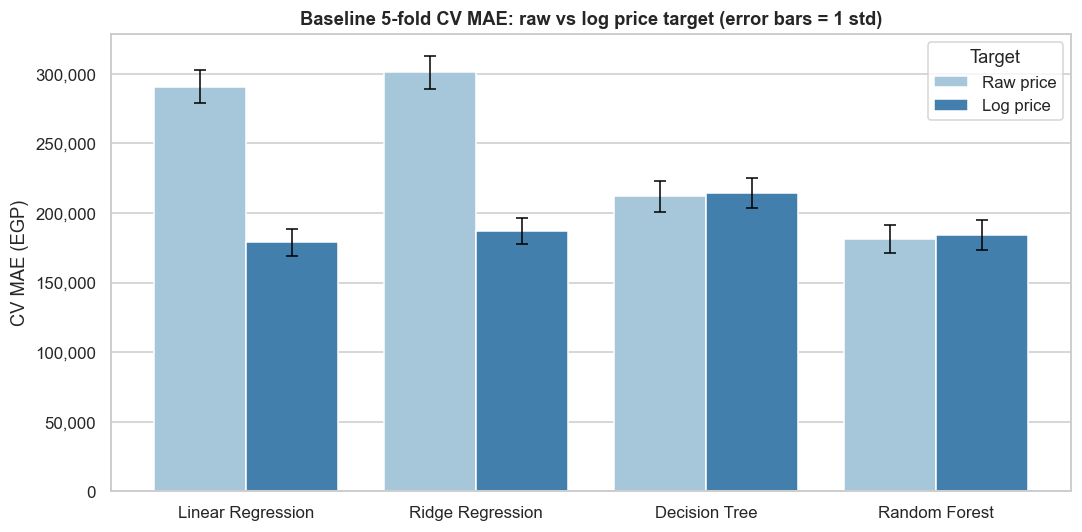

In [21]:
fig, ax = plt.subplots(figsize=(10, 5))
order = list(BASELINE_MODELS)
sns.barplot(data=baseline_results, x='Model', y='MAE', hue='Target', order=order,
            palette=['#9ecae1', '#3182bd'], ax=ax)
for container, target_name in zip(ax.containers, ['Raw price', 'Log price']):
    stds = baseline_results.set_index(['Target', 'Model']).loc[target_name].reindex(order)['MAE_std']
    centers = [bar.get_x() + bar.get_width() / 2 for bar in container]
    ax.errorbar(centers, [bar.get_height() for bar in container], yerr=stds.to_numpy(),
                fmt='none', ecolor='black', capsize=4, linewidth=1)
ax.set_title('Baseline 5-fold CV MAE: raw vs log price target (error bars = 1 std)')
ax.set_xlabel('')
ax.set_ylabel('CV MAE (EGP)')
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
plt.tight_layout()
save_figure(fig, 'baseline_target_comparison.png')
plt.show()

## 9. Hyperparameter tuning

Every search uses the same 5 CV folds on the training set and refits the best configuration (by CV MAE) on the whole training set. Each model is tuned on the target chosen in Section 8.

- **Ridge**: `GridSearchCV` over 25 values of the regularisation strength `alpha`, log-spaced from 10⁻³ to 10³.
- **Decision tree**: `GridSearchCV` over depth and the minimum samples needed to split a node or form a leaf. These parameters control how far the tree can overfit (90 combinations).
- **Random forest**: `RandomizedSearchCV` with 60 sampled configurations. Each fit is far more expensive, so random sampling covers a wider space (number of trees, depth, leaf size, features per split) at a fraction of the cost of a full grid.

In [22]:
def model_params(prefix_params: dict) -> dict:
    """Strip the pipeline prefix from search parameters, e.g. regressor__model__alpha -> alpha."""
    return {key.replace('regressor__model__', ''): value for key, value in prefix_params.items()}


def run_search(search, label: str):
    start = time.perf_counter()
    search.fit(X_train, y_train)
    best = search.cv_results_
    i = search.best_index_
    print(f'{label}: {time.perf_counter() - start:,.0f}s, best CV MAE = {-best["mean_test_MAE"][i]:,.0f} EGP')
    print(f'  best params: {model_params(search.best_params_)}')
    return search


ridge_search = run_search(GridSearchCV(
    build_model(Ridge(random_state=RANDOM_STATE), USE_LOG_TARGET['Ridge Regression']),
    param_grid={'regressor__model__alpha': np.logspace(-3, 3, 25)},
    cv=CV, scoring=SCORING, refit=PRIMARY_METRIC, n_jobs=-1, return_train_score=True,
), 'Ridge (GridSearchCV)')

Ridge (GridSearchCV): 5s, best CV MAE = 178,218 EGP
  best params: {'alpha': np.float64(0.05623413251903491)}


In [23]:
tree_search = run_search(GridSearchCV(
    build_model(DecisionTreeRegressor(random_state=RANDOM_STATE), USE_LOG_TARGET['Decision Tree']),
    param_grid={
        'regressor__model__max_depth': [5, 10, 15, 20, 25, None],
        'regressor__model__min_samples_split': [2, 10, 20],
        'regressor__model__min_samples_leaf': [1, 2, 5, 10, 20],
    },
    cv=CV, scoring=SCORING, refit=PRIMARY_METRIC, n_jobs=-1, return_train_score=True,
), 'Decision tree (GridSearchCV)')

Decision tree (GridSearchCV): 12s, best CV MAE = 209,486 EGP
  best params: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 10}


In [24]:
forest_search = run_search(RandomizedSearchCV(
    build_model(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1), USE_LOG_TARGET['Random Forest']),
    param_distributions={
        'regressor__model__n_estimators': randint(100, 501),
        'regressor__model__max_depth': [None, 10, 20, 30, 40],
        'regressor__model__min_samples_split': [2, 5, 10],
        'regressor__model__min_samples_leaf': [1, 2, 4, 8],
        'regressor__model__max_features': ['sqrt', 0.3, 0.5, 1.0],
    },
    n_iter=60, cv=CV, scoring=SCORING, refit=PRIMARY_METRIC, n_jobs=-1,
    return_train_score=True, random_state=RANDOM_STATE,
), 'Random forest (RandomizedSearchCV)')

Random forest (RandomizedSearchCV): 458s, best CV MAE = 180,815 EGP
  best params: {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 330}


### Tuning summary

The table compares each model's default (Section 8) and tuned CV scores. It also reports the gap between **training** and **validation** MAE as an indicator of overfitting.

In [25]:
SEARCHES = {'Ridge Regression': ridge_search, 'Decision Tree': tree_search, 'Random Forest': forest_search}

tuning_rows = []
for model_name, search in SEARCHES.items():
    res, i = search.cv_results_, search.best_index_
    default = best_target_rows.set_index('Model').loc[model_name]
    tuning_rows.append({
        'Model': model_name,
        'Target': 'log price' if USE_LOG_TARGET[model_name] else 'raw price',
        'Default CV MAE': default['MAE'],
        'Tuned CV MAE': -res['mean_test_MAE'][i],
        'Tuned CV MAE std': res['std_test_MAE'][i],
        'Tuned train MAE': -res['mean_train_MAE'][i],
        'Tuned CV R2': res['mean_test_R2'][i],
        'Tuned CV MAPE': -100 * res['mean_test_MAPE'][i],
        'Best parameters': model_params(search.best_params_),
    })
tuning_summary = pd.DataFrame(tuning_rows)
tuning_summary['MAE improvement %'] = 100 * (1 - tuning_summary['Tuned CV MAE'] / tuning_summary['Default CV MAE'])

display(tuning_summary.style.format({
    'Default CV MAE': '{:,.0f}', 'Tuned CV MAE': '{:,.0f}', 'Tuned CV MAE std': '{:,.0f}',
    'Tuned train MAE': '{:,.0f}', 'Tuned CV R2': '{:.3f}', 'Tuned CV MAPE': '{:.1f}%',
    'MAE improvement %': '{:.1f}%',
}).hide(axis='index'))

Model,Target,Default CV MAE,Tuned CV MAE,Tuned CV MAE std,Tuned train MAE,Tuned CV R2,Tuned CV MAPE,Best parameters,MAE improvement %
Ridge Regression,log price,"187,381","178,218","9,484","135,537",0.828,19.6%,{'alpha': np.float64(0.05623413251903491)},4.9%
Decision Tree,raw price,"212,014","209,486","14,594","84,171",0.757,22.3%,"{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 10}",1.2%
Random Forest,raw price,"181,414","180,815","10,528","86,105",0.813,20.8%,"{'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 330}",0.3%


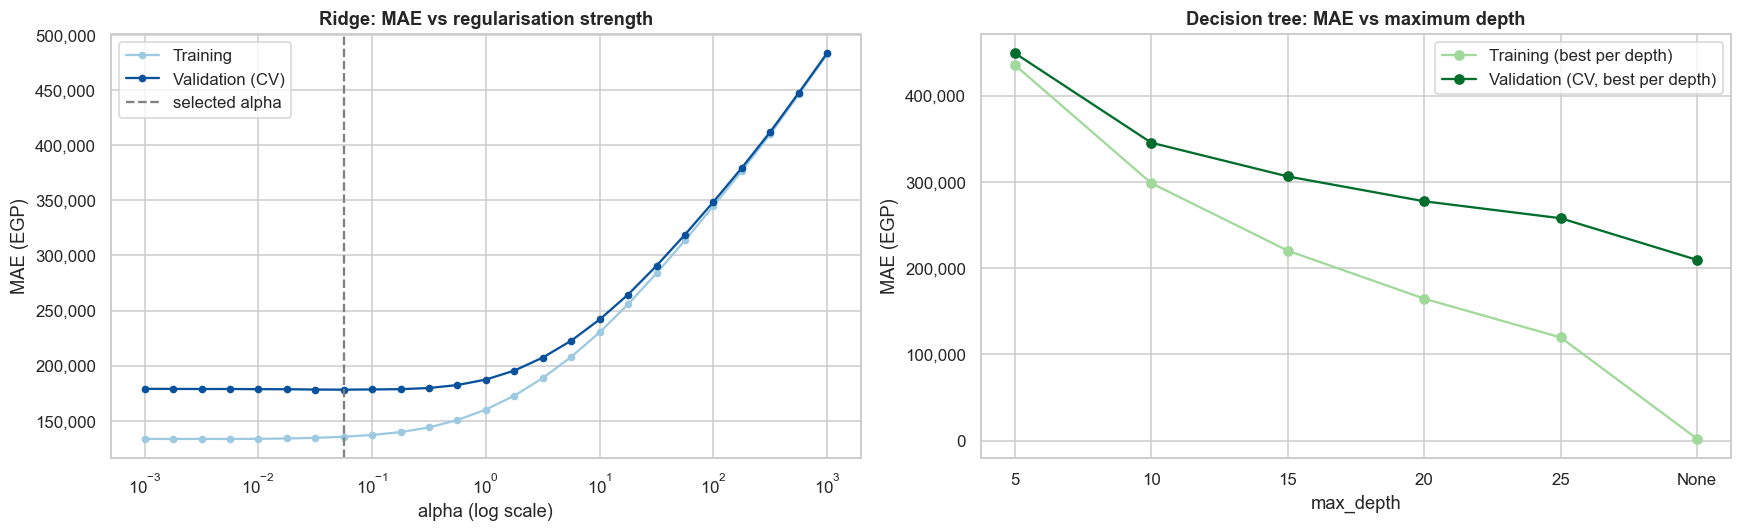

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

ridge_curve = pd.DataFrame({
    'alpha': ridge_search.cv_results_['param_regressor__model__alpha'].astype(float),
    'Validation (CV)': -ridge_search.cv_results_['mean_test_MAE'],
    'Training': -ridge_search.cv_results_['mean_train_MAE'],
})
for column, color in [('Training', '#9ecae1'), ('Validation (CV)', '#08519c')]:
    axes[0].plot(ridge_curve['alpha'], ridge_curve[column], marker='o', markersize=4, label=column, color=color)
axes[0].axvline(ridge_search.best_params_['regressor__model__alpha'], color='grey', linestyle='--', label='selected alpha')
axes[0].set_xscale('log')
axes[0].set_title('Ridge: MAE vs regularisation strength')
axes[0].set_xlabel('alpha (log scale)')
axes[0].set_ylabel('MAE (EGP)')
axes[0].legend()

tree_results = pd.DataFrame(tree_search.cv_results_)
tree_results['depth'] = tree_results['param_regressor__model__max_depth'].map(lambda d: 'None' if d is None else str(d))
tree_curve = tree_results.groupby('depth', sort=False).agg(
    validation=('mean_test_MAE', 'max'), training=('mean_train_MAE', 'max')
).mul(-1)
depth_order = ['5', '10', '15', '20', '25', 'None']
tree_curve = tree_curve.reindex(depth_order)
axes[1].plot(depth_order, tree_curve['training'], marker='o', label='Training (best per depth)', color='#a1d99b')
axes[1].plot(depth_order, tree_curve['validation'], marker='o', label='Validation (CV, best per depth)', color='#006d2c')
axes[1].set_title('Decision tree: MAE vs maximum depth')
axes[1].set_xlabel('max_depth')
axes[1].set_ylabel('MAE (EGP)')
axes[1].legend()

for ax in axes:
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
plt.tight_layout()
save_figure(fig, 'tuning_curves.png')
plt.show()

## 10. K-Means ablation: does the cluster feature help?

To measure what the unsupervised step contributes, each model is cross-validated again with its tuned hyperparameters and chosen target, but **without** the K-Means cluster columns. The folds are identical, so the difference is due only to the cluster feature.

The ablation is also used for feature selection: a model keeps the cluster feature only if it **lowers** that model's CV MAE. The tuned hyperparameters are reused in both variants.

In [27]:
FINAL_REGRESSORS = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(random_state=RANDOM_STATE, **model_params(ridge_search.best_params_)),
    'Decision Tree': DecisionTreeRegressor(random_state=RANDOM_STATE, **model_params(tree_search.best_params_)),
    'Random Forest': RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1, **model_params(forest_search.best_params_)),
}

ablation_rows = []
for model_name, regressor in FINAL_REGRESSORS.items():
    row = {'Model': model_name}
    for label, use_clusters in [('With clusters', True), ('Without clusters', False)]:
        results = cross_validate(
            build_model(clone(regressor), USE_LOG_TARGET[model_name], use_clusters=use_clusters),
            X_train, y_train, cv=CV, scoring={'MAE': SCORING['MAE']},
        )
        row[f'CV MAE {label.lower()}'] = -results['test_MAE'].mean()
    ablation_rows.append(row)

kmeans_ablation = pd.DataFrame(ablation_rows)
kmeans_ablation['Change from clusters (EGP)'] = (
    kmeans_ablation['CV MAE with clusters'] - kmeans_ablation['CV MAE without clusters']
)
kmeans_ablation['Change %'] = 100 * kmeans_ablation['Change from clusters (EGP)'] / kmeans_ablation['CV MAE without clusters']
display(kmeans_ablation.style.format({
    'CV MAE with clusters': '{:,.0f}', 'CV MAE without clusters': '{:,.0f}',
    'Change from clusters (EGP)': '{:+,.0f}', 'Change %': '{:+.2f}%',
}).hide(axis='index'))
USE_CLUSTERS = dict(zip(kmeans_ablation['Model'], kmeans_ablation['Change from clusters (EGP)'] < 0))
print('Negative change = the K-Means cluster feature lowered (improved) the CV MAE.')
for model_name, use_clusters in USE_CLUSTERS.items():
    print(f'  {model_name:<18} -> {"keep" if use_clusters else "drop"} cluster feature')

Model,CV MAE with clusters,CV MAE without clusters,Change from clusters (EGP),Change %
Linear Regression,"178,930","178,425",+506,+0.28%
Ridge Regression,"178,218","177,579",+639,+0.36%
Decision Tree,"209,486","211,785","-2,299",-1.09%
Random Forest,"180,815","180,800",+15,+0.01%


Negative change = the K-Means cluster feature lowered (improved) the CV MAE.
  Linear Regression  -> drop cluster feature
  Ridge Regression   -> drop cluster feature
  Decision Tree      -> keep cluster feature
  Random Forest      -> drop cluster feature


## 11. Final evaluation on the held-out test set

The final configurations (chosen target, tuned hyperparameters, and cluster feature only where it helped) are refitted on the full training set and evaluated **once** on the untouched test set. A median-price predictor (`DummyRegressor`) is included as a naive reference point. The model recommended for deployment is the one with the lowest **cross-validated** MAE. The test set is used only to confirm that choice, not to make it.

In [28]:
DISPLAY_NAMES = {
    'Linear Regression': 'Linear Regression',
    'Ridge Regression': 'Ridge Regression (tuned)',
    'Decision Tree': 'Decision Tree (tuned)',
    'Random Forest': 'Random Forest (tuned)',
}
final_models = {'Median baseline': DummyRegressor(strategy='median').fit(X_train, y_train)}
for model_name, regressor in FINAL_REGRESSORS.items():
    final_models[DISPLAY_NAMES[model_name]] = build_model(
        clone(regressor), USE_LOG_TARGET[model_name], use_clusters=USE_CLUSTERS[model_name]
    ).fit(X_train, y_train)
test_predictions = {name: model.predict(X_test) for name, model in final_models.items()}

test_results = pd.DataFrame(
    [{'Model': name, **regression_metrics(y_test, pred)} for name, pred in test_predictions.items()]
).sort_values('MAE')
display(test_results.style.format(
    {'MAE': '{:,.0f}', 'RMSE': '{:,.0f}', 'R2': '{:.3f}', 'MAPE': '{:.1f}%'}
).hide(axis='index'))

# CV MAE of each final configuration (with or without clusters, as chosen in Section 10).
ablation_indexed = kmeans_ablation.set_index('Model')
cv_mae = {
    DISPLAY_NAMES[name]: ablation_indexed.loc[name, 'CV MAE with clusters' if USE_CLUSTERS[name] else 'CV MAE without clusters']
    for name in FINAL_REGRESSORS
}
BEST_MODEL_NAME = min(cv_mae, key=cv_mae.get)
print(f'Model selected by cross-validated MAE: {BEST_MODEL_NAME} (CV MAE {cv_mae[BEST_MODEL_NAME]:,.0f} EGP)')

Model,MAE,RMSE,R2,MAPE
Random Forest (tuned),"159,927","560,160",0.870,14.9%
Ridge Regression (tuned),"168,068","603,839",0.848,14.6%
Linear Regression,"169,030","596,636",0.852,14.9%
Decision Tree (tuned),"179,020","553,190",0.873,17.2%
Median baseline,"749,911","1,615,693",-0.085,92.1%


Model selected by cross-validated MAE: Ridge Regression (tuned) (CV MAE 177,579 EGP)


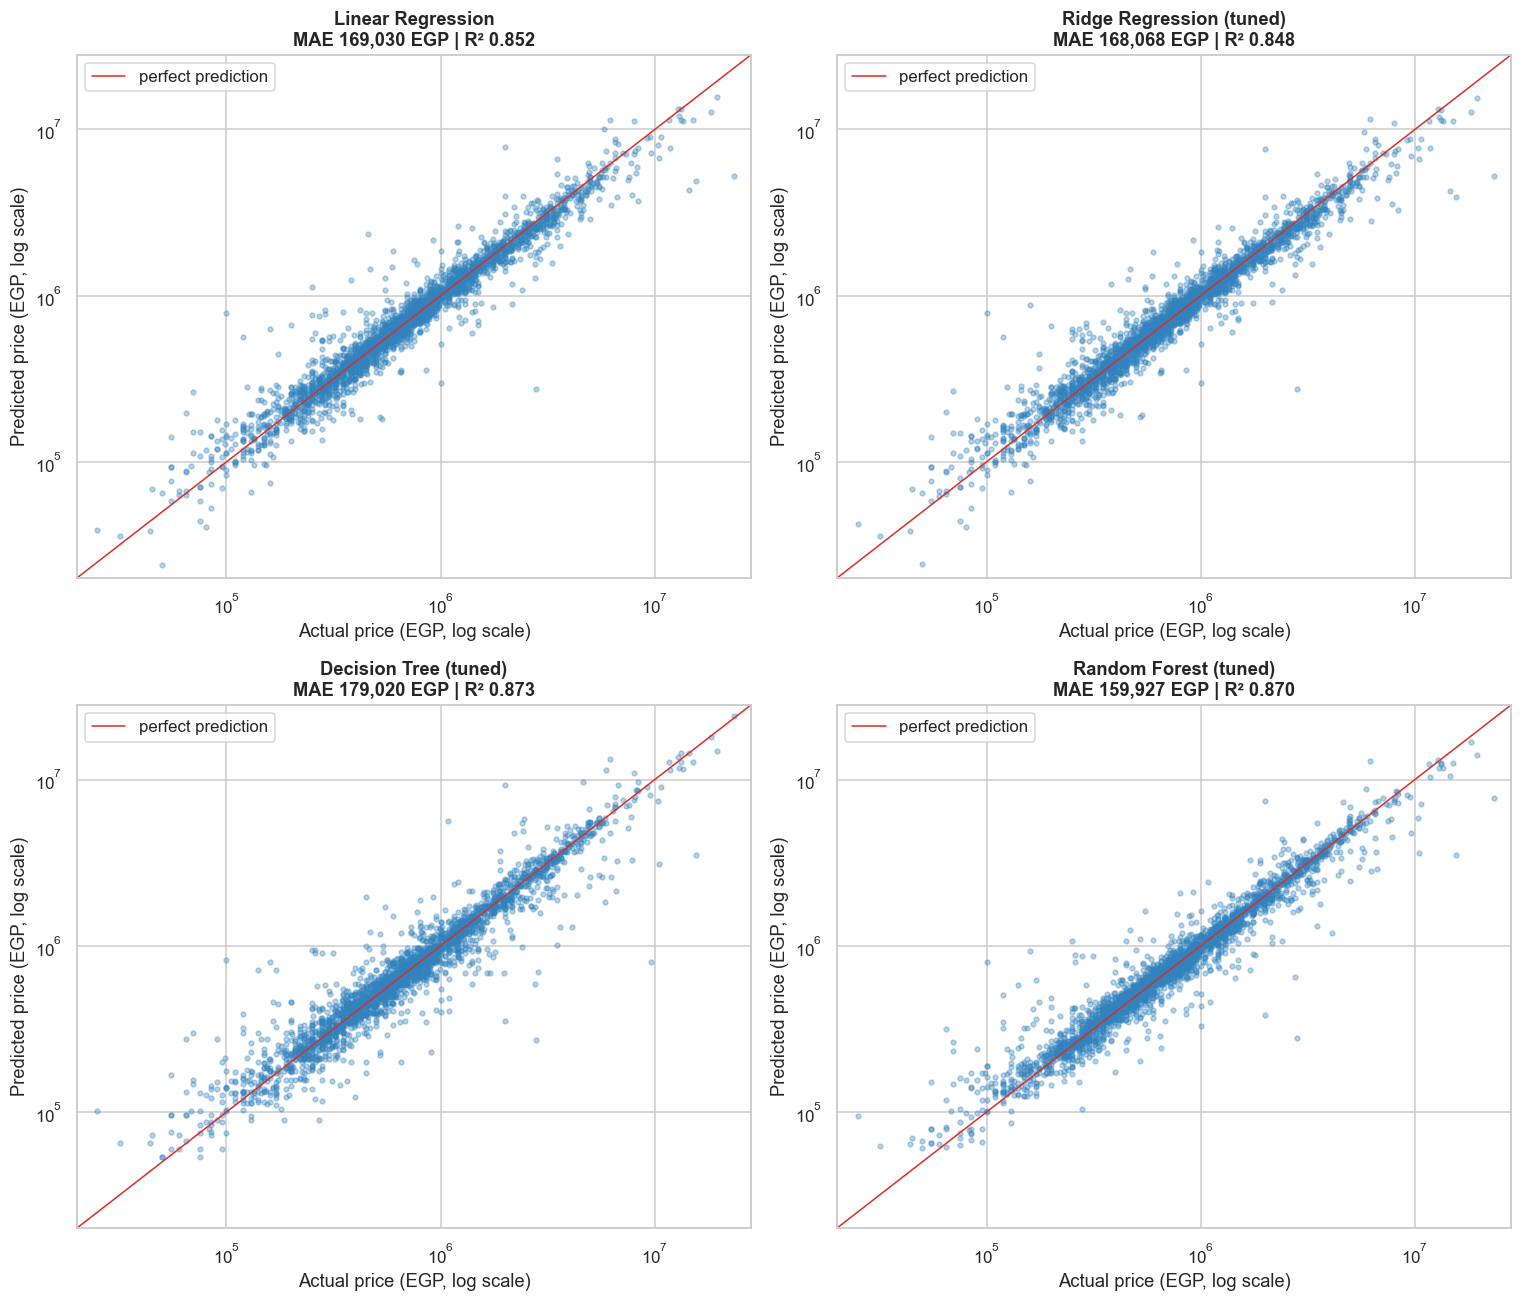

In [29]:
plot_models = [name for name in final_models if name != 'Median baseline']
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
limits = (y_test.min() * 0.8, y_test.max() * 1.2)
for ax, name in zip(axes.flat, plot_models):
    metrics = regression_metrics(y_test, test_predictions[name])
    ax.scatter(y_test, test_predictions[name], s=10, alpha=0.35, color='#3182bd')
    ax.plot(limits, limits, color='#de2d26', linewidth=1, label='perfect prediction')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_title(f'{name}\nMAE {metrics["MAE"]:,.0f} EGP | R² {metrics["R2"]:.3f}')
    ax.set_xlabel('Actual price (EGP, log scale)')
    ax.set_ylabel('Predicted price (EGP, log scale)')
    ax.legend(loc='upper left')
plt.tight_layout()
save_figure(fig, 'predicted_vs_actual.png')
plt.show()

### Error by price band

Absolute errors naturally grow with price. The table splits the test set into price quintiles and reports the MAE and MAPE of each model within each band. This shows *where* each model is reliable.

In [30]:
band_edges = y_train.quantile([0, 0.2, 0.4, 0.6, 0.8, 1.0]).to_numpy()
band_edges[0], band_edges[-1] = -np.inf, np.inf
band_labels = [
    f'≤{band_edges[1] / 1e3:,.0f}k',
    *[f'{lo / 1e3:,.0f}k–{hi / 1e3:,.0f}k' for lo, hi in zip(band_edges[1:-2], band_edges[2:-1])],
    f'>{band_edges[-2] / 1e3:,.0f}k',
]
test_bands = pd.cut(y_test, bins=band_edges, labels=band_labels)

band_rows = []
for name in plot_models:
    for band in band_labels:
        mask = (test_bands == band).to_numpy()
        band_rows.append({
            'Model': name, 'Price band (EGP)': band, 'Listings': int(mask.sum()),
            'MAE': mean_absolute_error(y_test[mask], test_predictions[name][mask]),
            'MAPE': 100 * mean_absolute_percentage_error(y_test[mask], test_predictions[name][mask]),
        })
band_errors = pd.DataFrame(band_rows)
display(
    band_errors.pivot(index='Price band (EGP)', columns='Model', values='MAPE')
    .reindex(band_labels)[plot_models]
    .style.format('{:.1f}%').set_caption('Test MAPE by price band (bands are training-price quintiles)')
)

Model,Linear Regression,Ridge Regression (tuned),Decision Tree (tuned),Random Forest (tuned)
Price band (EGP),,,,
≤340k,24.8%,24.5%,29.7%,27.4%
340k–580k,14.4%,13.8%,15.9%,13.0%
580k–825k,10.1%,9.9%,11.6%,9.3%
"825k–1,465k",11.2%,11.0%,13.1%,11.0%
">1,465k",13.9%,13.8%,15.9%,13.9%


### What drives the predictions?

Permutation importance measures how much the test MAE of the selected model increases when one **original** input column is randomly shuffled. Because the whole pipeline is permuted at the raw-column level, all one-hot columns of `model` (for example) are assessed together.

Feature,MAE increase (EGP),std
brand,"575,490","15,400"
year,"368,321","5,983"
model,"315,841","6,382"
mileage_km,"18,652","1,712"
transmission,"8,664",948
fuel,"2,415",284
governorate,702,176


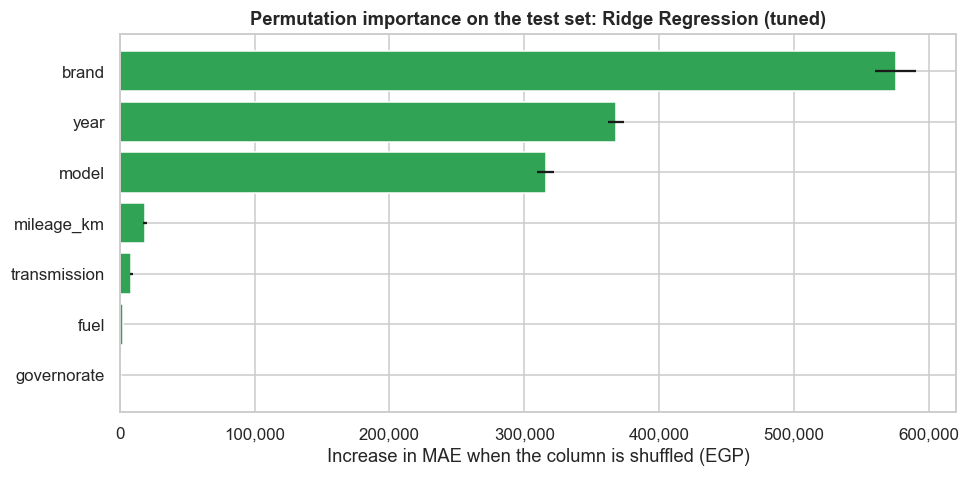

In [31]:
best_model = final_models[BEST_MODEL_NAME]
importance = permutation_importance(
    best_model, X_test, y_test, scoring='neg_mean_absolute_error',
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
)
importance_table = pd.DataFrame({
    'Feature': X_test.columns,
    'MAE increase (EGP)': importance.importances_mean,
    'std': importance.importances_std,
}).sort_values('MAE increase (EGP)', ascending=False)
display(importance_table.style.format({'MAE increase (EGP)': '{:,.0f}', 'std': '{:,.0f}'}).hide(axis='index'))

fig, ax = plt.subplots(figsize=(9, 4.5))
ordered = importance_table.sort_values('MAE increase (EGP)')
ax.barh(ordered['Feature'], ordered['MAE increase (EGP)'], xerr=ordered['std'], color='#31a354')
ax.set_title(f'Permutation importance on the test set: {BEST_MODEL_NAME}')
ax.set_xlabel('Increase in MAE when the column is shuffled (EGP)')
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
plt.tight_layout()
save_figure(fig, 'permutation_importance.png')
plt.show()

## 12. Summary

In [32]:
best_test = test_results.set_index('Model').loc[BEST_MODEL_NAME]
baseline_test = test_results.set_index('Model').loc['Median baseline']
target_lines = '\n'.join(
    f'  - {name}: **{"log" if log else "raw"} price**' for name, log in USE_LOG_TARGET.items()
)
display(Markdown(f'''### Key results

- Modelling data: **{len(cars):,} listings** after validation ({len(X_train):,} train / {len(X_test):,} test), seed {RANDOM_STATE}.
- K-Means on scaled year and mileage selected **k = {N_CLUSTERS}** (highest silhouette). The cluster feature was kept for: {', '.join(n for n, keep in USE_CLUSTERS.items() if keep) or 'none'}.
- Target chosen by baseline CV MAE:
{target_lines}
- Selected model (lowest CV MAE): **{BEST_MODEL_NAME}**, with CV MAE {cv_mae[BEST_MODEL_NAME]:,.0f} EGP.
- On the held-out test set it achieves **MAE {best_test["MAE"]:,.0f} EGP**, RMSE {best_test["RMSE"]:,.0f} EGP, R² {best_test["R2"]:.3f}, MAPE {best_test["MAPE"]:.1f}%. The median-price baseline scores MAE {baseline_test["MAE"]:,.0f} EGP and R² {baseline_test["R2"]:.3f}.
- The most important input by permutation importance is **`{importance_table.iloc[0]["Feature"]}`**.
'''))

### Key results

- Modelling data: **14,487 listings** after validation (11,589 train / 2,898 test), seed 42.
- K-Means on scaled year and mileage selected **k = 3** (highest silhouette). The cluster feature was kept for: Decision Tree.
- Target chosen by baseline CV MAE:
  - Decision Tree: **raw price**
  - Linear Regression: **log price**
  - Random Forest: **raw price**
  - Ridge Regression: **log price**
- Selected model (lowest CV MAE): **Ridge Regression (tuned)**, with CV MAE 177,579 EGP.
- On the held-out test set it achieves **MAE 168,068 EGP**, RMSE 603,839 EGP, R² 0.848, MAPE 14.6%. The median-price baseline scores MAE 749,911 EGP and R² -0.085.
- The most important input by permutation importance is **`brand`**.
